# Challenge 2 · Dataset & EDA (B)
**Nguyễn Minh Triết · 3124411320**

Nguồn: ba CSV trong ZIP Kaggle do người dùng cung cấp. Notebook chỉ đọc dữ liệu gốc,
không sửa `features.py`, không tuning mô hình và không nộp Kaggle.
Mục tiêu: kiểm chứng bảy nhận xét của A, bàn giao C, viết mục 3 và xuất hình 300 dpi.
Các mã Class 0–10 được giữ nguyên vì chưa có ánh xạ tên thể loại được xác minh.

Chạy từ đầu: cài `code/requirements_B.txt`, chọn kernel của môi trường đó rồi Restart & Run All.
Notebook tự tìm gốc dự án từ thư mục hiện tại; dùng seed và folds của `common.py`.
Đầu ra: `eda_findings.md`, `paper/03_dataset_eda.md`, `paper/figures/B_01_class_distribution.png` và `B_02_duration_and_features.png`.
Các hình bổ sung và số liệu kiểm chứng giữ trực tiếp trong notebook. Chỉ các đầu ra của B được ghi đè khi chạy lại.


In [1]:
from pathlib import Path
import sys, json, hashlib, platform, io
from datetime import datetime, timezone
from importlib.metadata import version
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "code/common.py").exists() and (p / "data/train.csv").exists())
sys.path.insert(0, str(ROOT / "code"))
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image, Markdown
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from common import load_data, get_folds, SEED, N_FOLDS
train, test, sample = load_data()
CLASSES = sorted(train.Class.unique().tolist())
NUMERIC = [c for c in train.select_dtypes(include=np.number).columns if c not in ["Id", "Class"]]
FIGURES = ROOT / "paper/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=.9)
PALETTE = dict(zip(CLASSES, sns.color_palette("tab20", len(CLASSES))))
INPUT_HASHES = {name: hashlib.sha256((ROOT / "data" / name).read_bytes()).hexdigest()
                for name in ["train.csv", "test.csv", "sample_submission.csv"]}
def save_figure(fig, name):
    # Paper requires two exported figures; supplementary EDA stays in notebook.
    if name in ["B_01_class_distribution.png", "B_02_duration_and_features.png"]:
        path = FIGURES / name
        fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
        display(Image(filename=str(path), width=1050))
    else:
        buffer = io.BytesIO()
        fig.savefig(buffer, format="png", dpi=300, bbox_inches="tight", facecolor="white")
        display(Image(data=buffer.getvalue(), width=1050))
    plt.close(fig)
print("Python", platform.python_version(), "Seed", SEED, "CV folds", N_FOLDS)


Python 3.12.10 Seed 42 CV folds 5


## 1. Kiểm tra cấu trúc, nhãn, ID và trùng lặp
Kiểm tra trùng cả khi giữ ID và khi bỏ ID; cùng artist/track chưa chắc là cùng bản ghi.
Test không có nhãn, nên chỉ so phân phối và độ phủ. Các assertion dừng notebook nếu
cấu trúc khác bộ dữ liệu đã bàn giao; không âm thầm sửa dữ liệu.


,dtype,missing_train,missing_test,unique_train
Id,int64,0,0.0,14396
Artist Name,str,0,0.0,7913
Track Name,str,0,0.0,12455
Popularity,float64,333,95.0,101
danceability,float64,0,0.0,887
energy,float64,0,0.0,1156
key,float64,1609,405.0,12
loudness,float64,0,0.0,8051
mode,int64,0,0.0,2
speechiness,float64,0,0.0,1177


train_full                   0
train_without_id             0
train_without_id_label    1081
test_full                    0
test_without_id             71
Name: Duplicate rows, dtype: int64

,n,percent
Class,,
0,500,3.47
1,1098,7.63
2,1018,7.07
3,322,2.24
4,310,2.15
5,1157,8.04
6,2069,14.37
7,461,3.20
8,1483,10.30


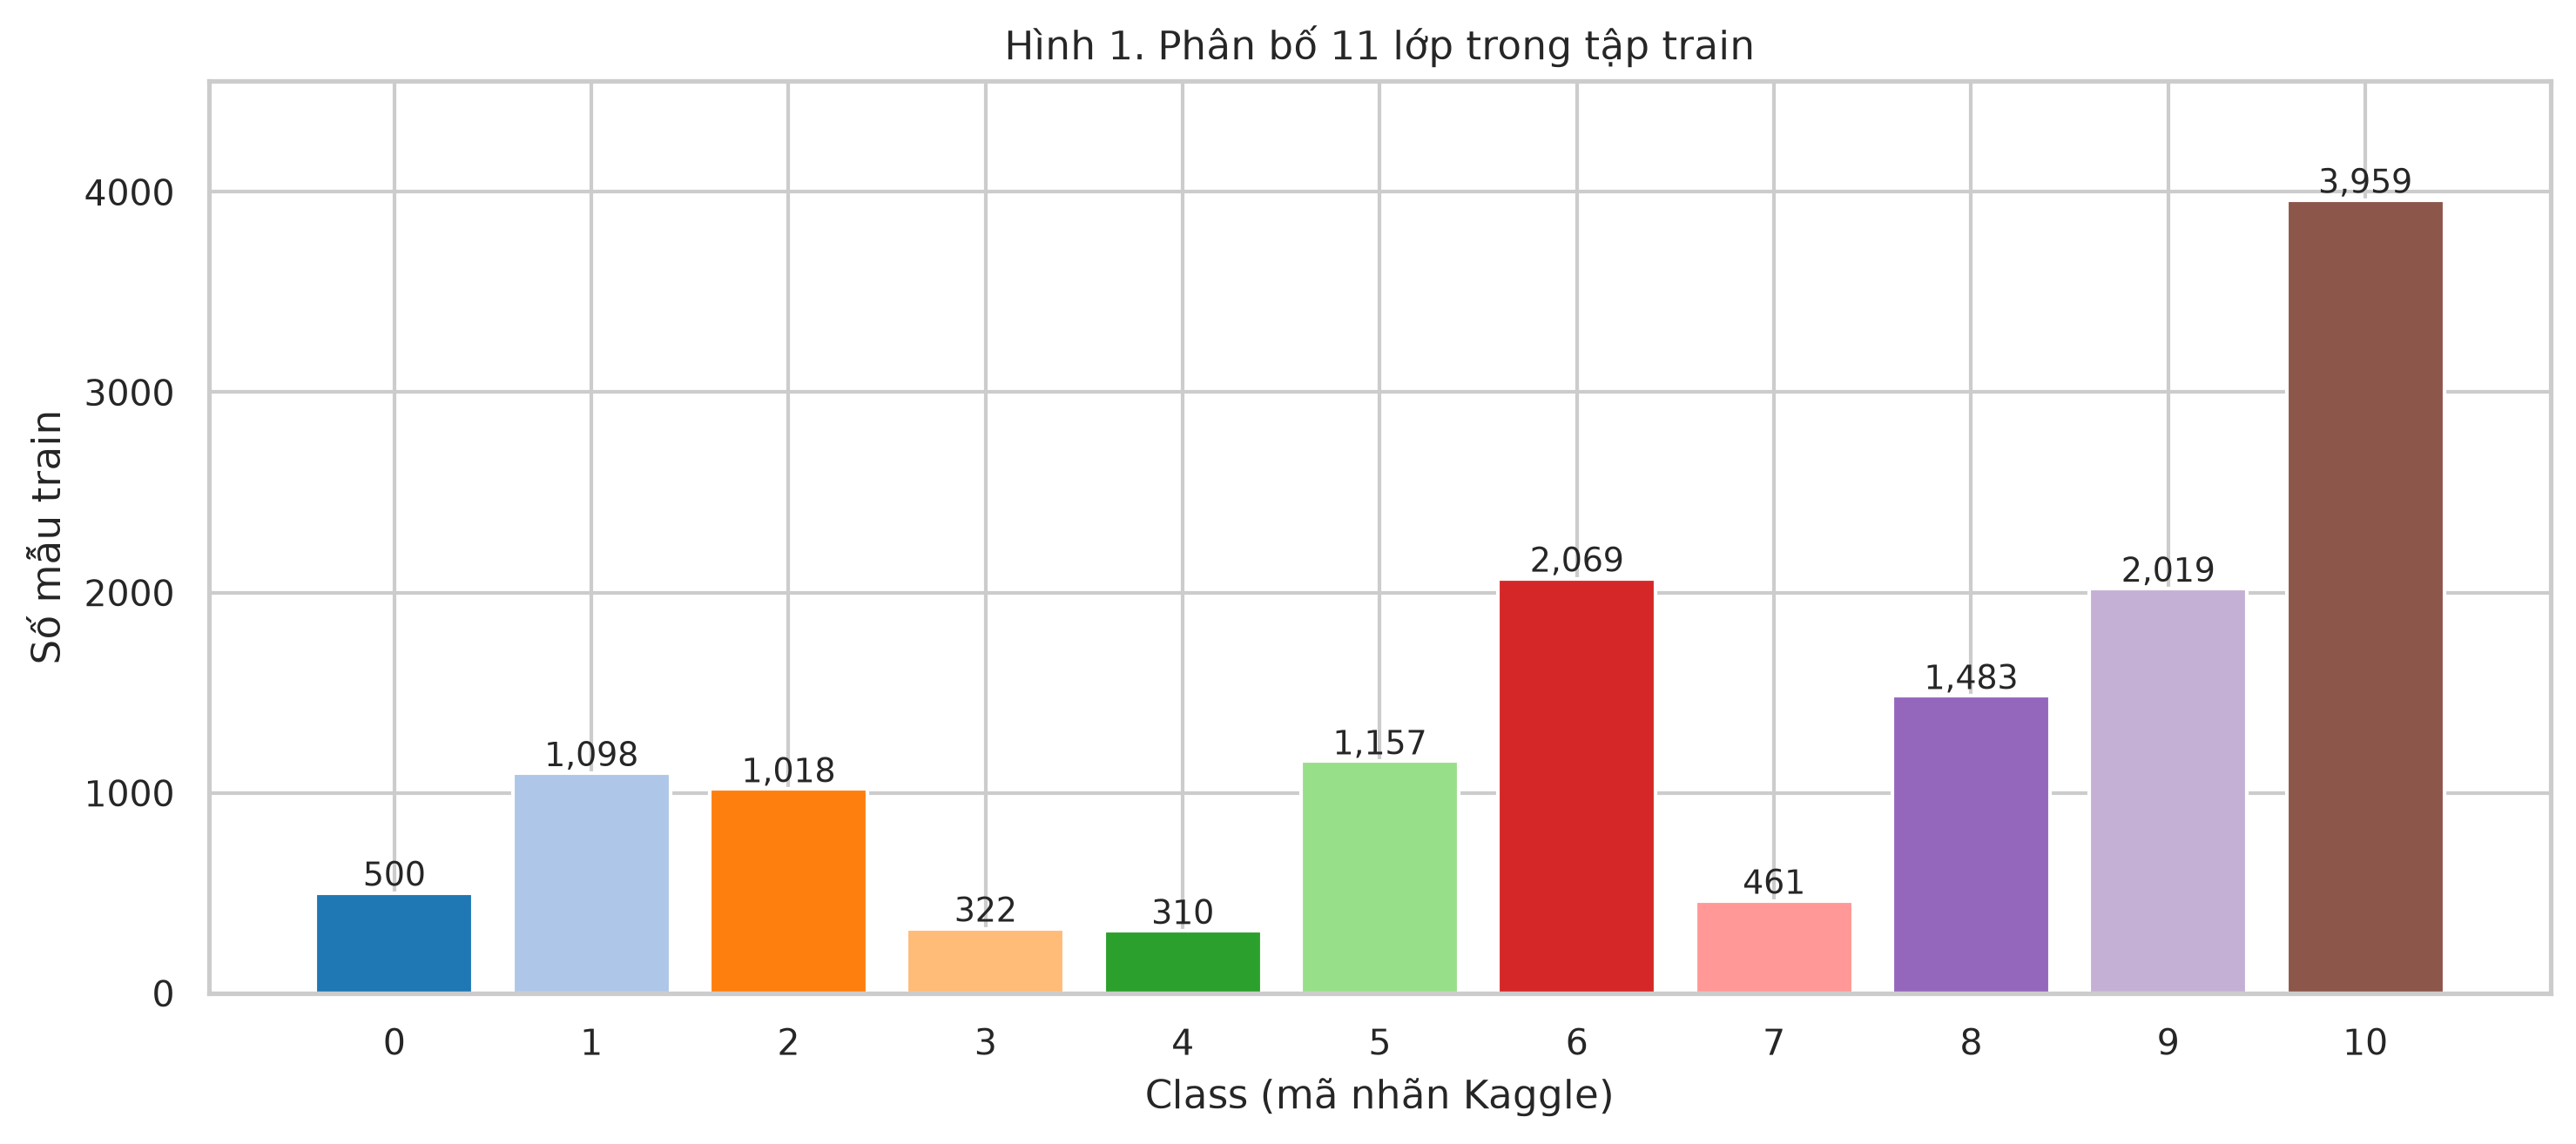

In [2]:
assert train.shape == (14396, 18), train.shape
assert test.shape == (3600, 17), test.shape
assert sample.shape == (3600, 2) and list(sample.columns) == ["Id", "Class"]
assert set(train.columns) - {"Class"} == set(test.columns)
assert CLASSES == list(range(11)) and not train.Class.isna().any()
assert train.Id.is_unique and test.Id.is_unique
assert not set(train.Id) & set(test.Id)
assert np.array_equal(test.Id.to_numpy(), sample.Id.to_numpy())
assert np.isfinite(train[NUMERIC].dropna().to_numpy()).all()
duplicates = {
    "train_full": int(train.duplicated().sum()),
    "train_without_id": int(train.drop(columns="Id").duplicated().sum()),
    "train_without_id_label": int(train.drop(columns=["Id", "Class"]).duplicated().sum()),
    "test_full": int(test.duplicated().sum()),
    "test_without_id": int(test.drop(columns="Id").duplicated().sum()),
}
schema = pd.DataFrame({"dtype": train.dtypes.astype(str), "missing_train": train.isna().sum(),
                       "missing_test": test.isna().sum().reindex(train.columns),
                       "unique_train": train.nunique(dropna=False)})
display(schema)
display(pd.Series(duplicates, name="Duplicate rows"))
class_counts = train.Class.value_counts().reindex(CLASSES)
class_table = pd.DataFrame({"n": class_counts, "percent": class_counts / len(train) * 100})
display(class_table.round(2))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar([str(x) for x in CLASSES], class_counts, color=[PALETTE[x] for x in CLASSES])
for i, n in enumerate(class_counts): ax.text(i, n + 35, f"{n:,}", ha="center", fontsize=9)
ax.set(xlabel="Class (mã nhãn Kaggle)", ylabel="Số mẫu train", title="Hình 1. Phân bố 11 lớp trong tập train", ylim=(0, class_counts.max()*1.15))
fig.tight_layout()
save_figure(fig, "B_01_class_distribution.png")


## 2. `duration_in min/ms`: kiểm chứng hiện tượng lẫn thang đo
Quy tắc dưới đây là **giả thuyết đơn vị** theo A: giá trị <30 được hiểu là phút,
còn lại là mili giây. Kiểm tra khoảng giữa 30 và 1000 và độ nhạy ngưỡng để bàn giao C.
Không thể khẳng định đơn vị từng dòng chỉ từ tên cột. Giữ nguyên cột gốc; chỉ tạo
bản quy đổi để mô tả. Cờ nguồn/đơn vị có thể phản ánh cách thu thập, không phải âm nhạc.


,n_lt30,pct_lt30,n_30_to_1000,threshold_disagreements,small_range,large_range
train,2075,14.413726,0,0,"[0.50165, 29.886]","[55775.0, 1477187.0]"
test,505,14.027778,0,0,"[0.987117, 29.45]","[23320.0, 1412451.0]"


,sum,count,mean,percent
Class,,,,
0,500,500,1.000,100.000
1,0,1098,0.000,0.000
2,0,1018,0.000,0.000
3,322,322,1.000,100.000
4,310,310,1.000,100.000
5,0,1157,0.000,0.000
6,0,2069,0.000,0.000
7,461,461,1.000,100.000
8,0,1483,0.000,0.000


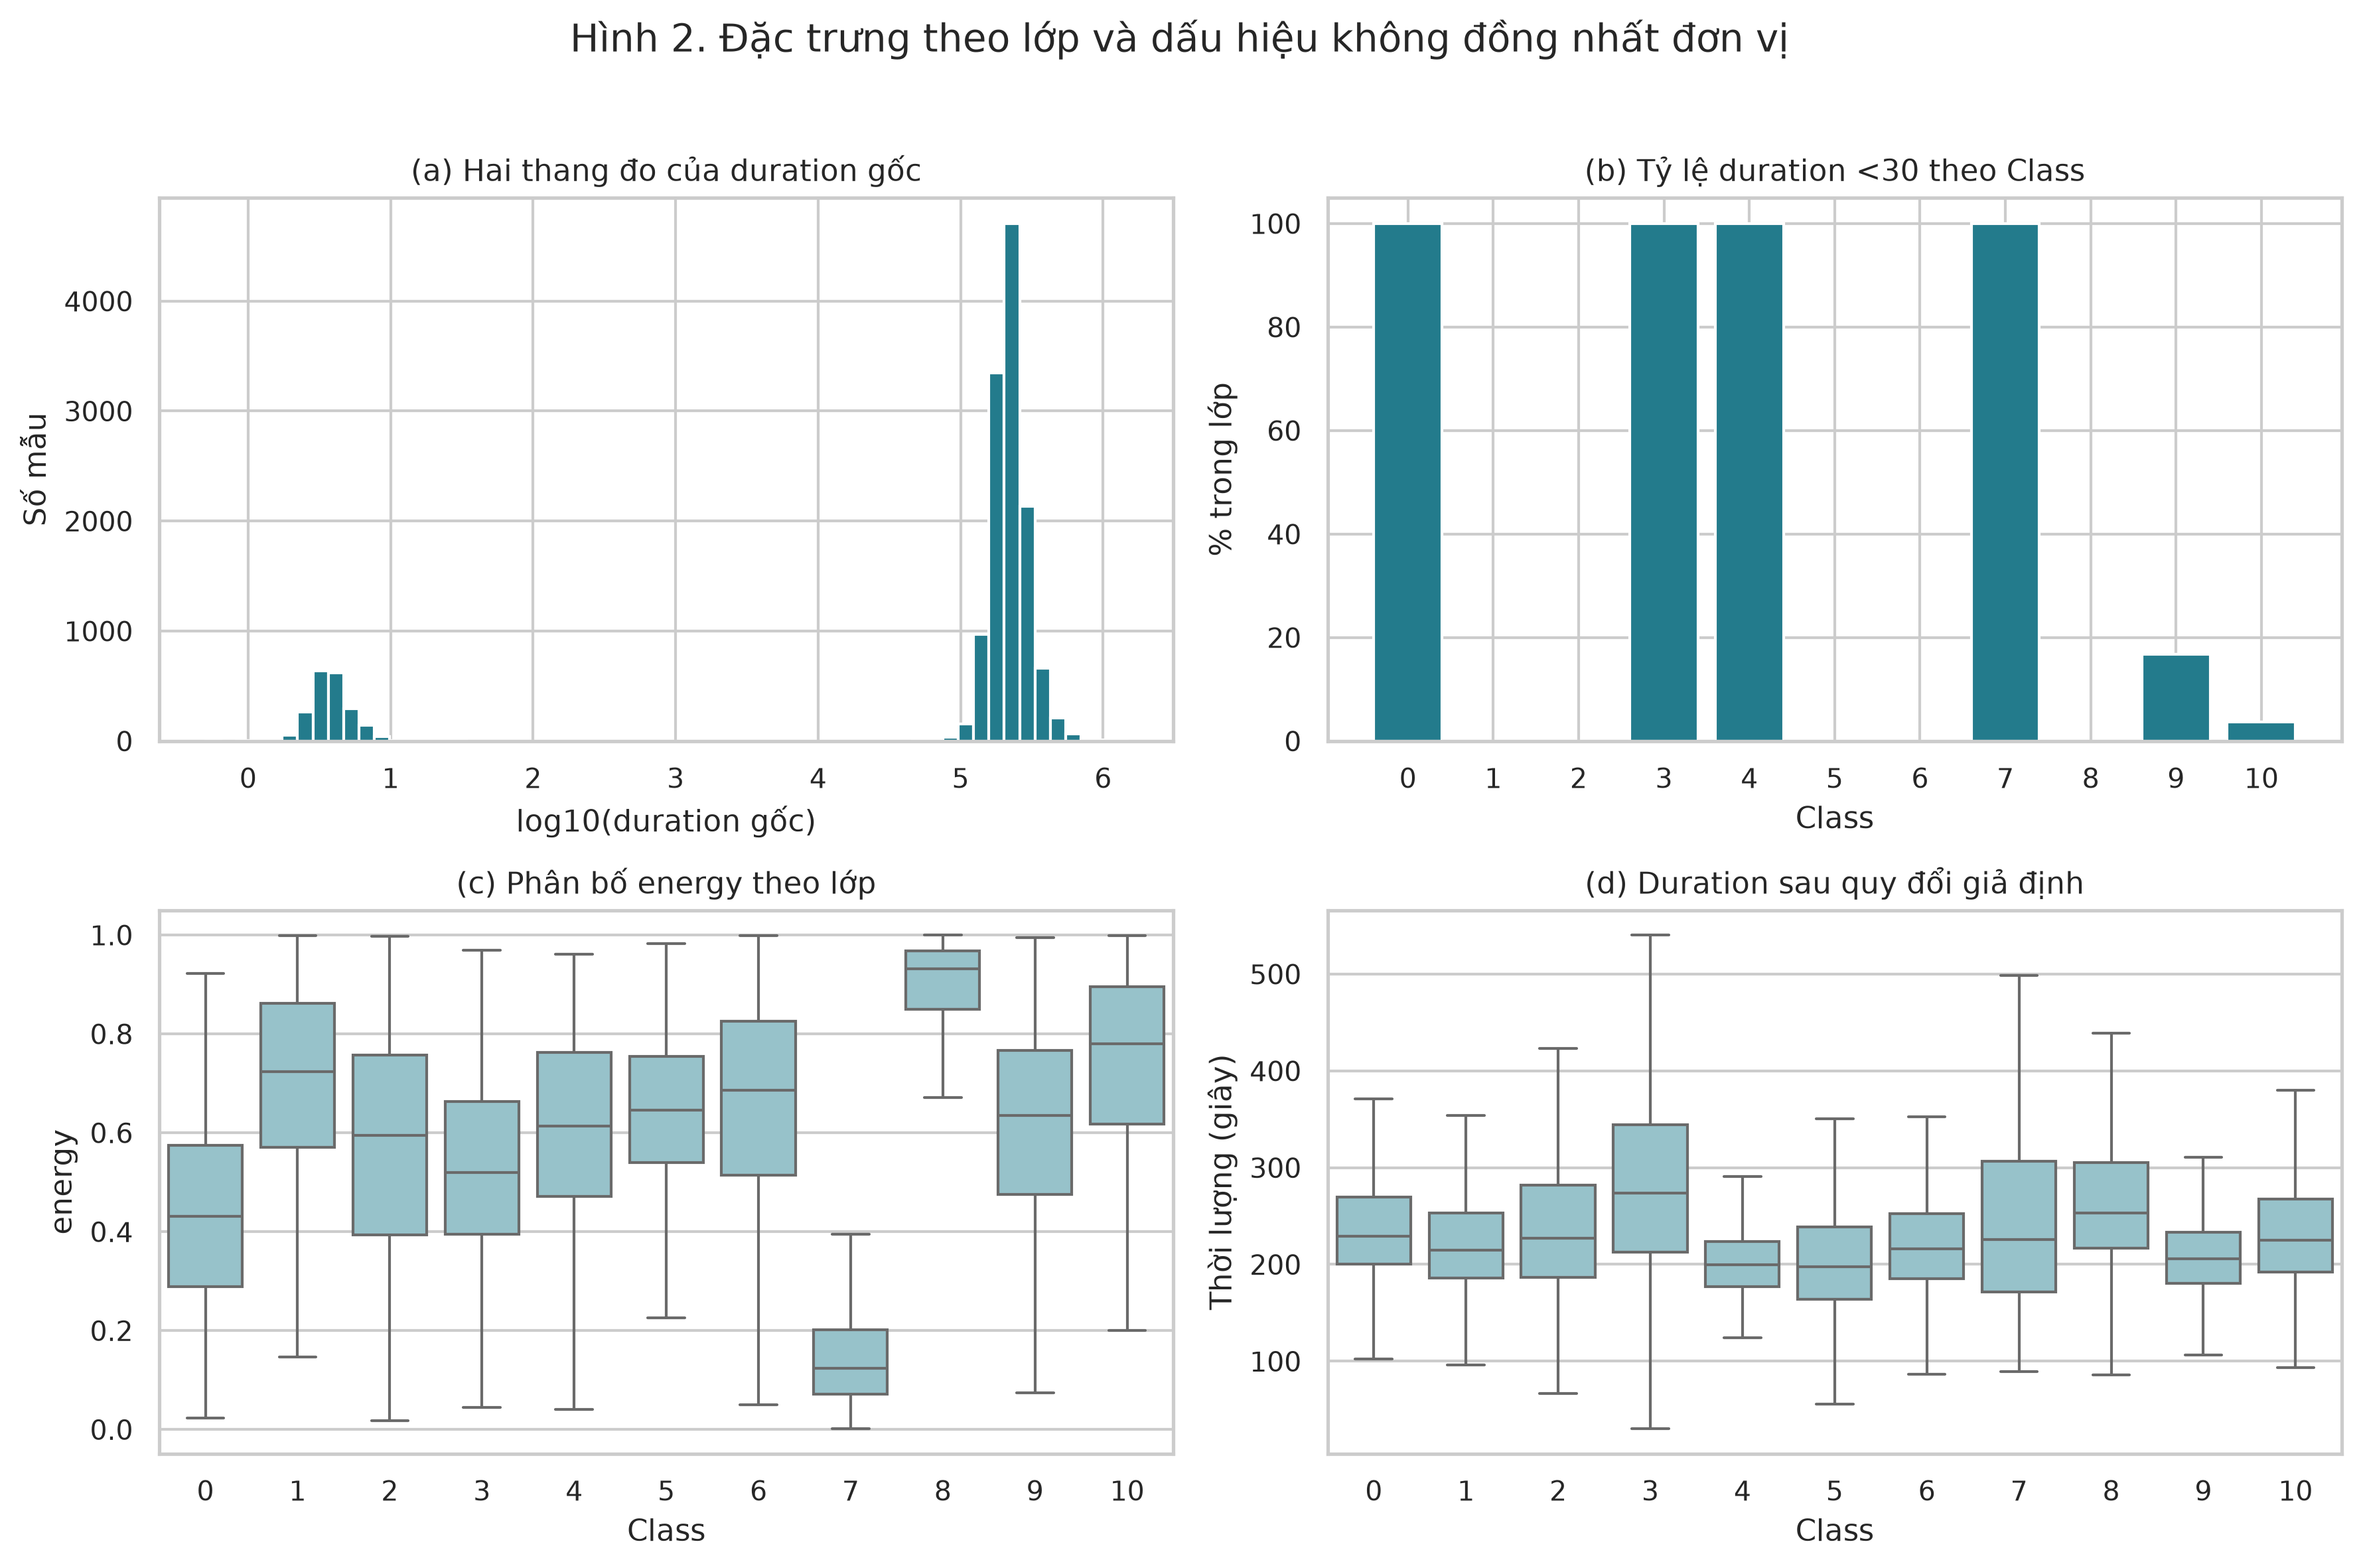

In [3]:
DURATION = "duration_in min/ms"
duration_records = {}
for name, frame in [("train", train), ("test", test)]:
    raw = frame[DURATION]
    flag30, flag1000 = raw.lt(30), raw.lt(1000)
    duration_records[name] = {
        "n_lt30": int(flag30.sum()), "pct_lt30": float(flag30.mean()*100),
        "n_30_to_1000": int((raw.ge(30) & raw.lt(1000)).sum()),
        "threshold_disagreements": int((flag30 != flag1000).sum()),
        "small_range": [float(raw[flag30].min()), float(raw[flag30].max())],
        "large_range": [float(raw[~flag30].min()), float(raw[~flag30].max())],
    }
duration_minutes = train[DURATION].lt(30)
duration_seconds = pd.Series(np.where(duration_minutes, train[DURATION]*60, train[DURATION]/1000), index=train.index)
duration_by_class = pd.DataFrame({"Class": train.Class, "flag": duration_minutes}).groupby("Class").flag.agg(["sum", "count", "mean"])
display(pd.DataFrame(duration_records).T)
display(duration_by_class.assign(percent=duration_by_class["mean"]*100).round(3))
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0,0].hist(np.log10(train[DURATION]), bins=60, color="#237b8c")
axes[0,0].set(title="(a) Hai thang đo của duration gốc", xlabel="log10(duration gốc)", ylabel="Số mẫu")
axes[0,1].bar([str(c) for c in CLASSES], duration_by_class["mean"]*100, color="#237b8c")
axes[0,1].set(title="(b) Tỷ lệ duration <30 theo Class", xlabel="Class", ylabel="% trong lớp", ylim=(0,105))
plot_data = train[["Class", "energy", "loudness"]].copy()
sns.boxplot(data=plot_data, x="Class", y="energy", showfliers=False, ax=axes[1,0], color="#8fc8d2")
axes[1,0].set(title="(c) Phân bố energy theo lớp", xlabel="Class", ylabel="energy")
dur_plot = pd.DataFrame({"Class":train.Class, "seconds":duration_seconds})
sns.boxplot(data=dur_plot, x="Class", y="seconds", showfliers=False, ax=axes[1,1], color="#8fc8d2")
axes[1,1].set(title="(d) Duration sau quy đổi giả định", xlabel="Class", ylabel="Thời lượng (giây)")
fig.suptitle("Hình 2. Đặc trưng theo lớp và dấu hiệu không đồng nhất đơn vị", fontsize=14)
fig.tight_layout(rect=(0,0,1,.96))
save_figure(fig, "B_02_duration_and_features.png")


## 3. Phân phối toàn bộ đặc trưng và ngoại lệ
Boxplot giữ các quan sát ngoại lệ; trục duration dùng log để nhìn được hai thang đo.
Bảng IQR chỉ đánh dấu giá trị xa phân phối, **không coi đó là lỗi nhập liệu**.
Không loại/cắt dữ liệu trong notebook B.


,count,mean,std,min,1%,25%,50%,75%,99%,max
Popularity,14063.0,44.5252,17.4189,1.0000,3.0000,33.0000,44.0000,56.0000,84.0000,100.000
danceability,14396.0,0.5431,0.1655,0.0596,0.1580,0.4320,0.5450,0.6580,0.9010,0.989
energy,14396.0,0.6624,0.2360,0.0012,0.0619,0.5080,0.6990,0.8610,0.9900,1.000
key,12787.0,5.9538,3.2000,1.0000,1.0000,3.0000,6.0000,9.0000,11.0000,11.000
loudness,14396.0,-7.9009,4.0574,-39.9520,-22.7518,-9.5380,-7.0135,-5.1620,-2.1709,1.342
mode,14396.0,0.6402,0.4799,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,1.000
speechiness,14396.0,0.0802,0.0852,0.0225,0.0253,0.0348,0.0471,0.0831,0.4240,0.955
acousticness,14396.0,0.2467,0.3109,0.0000,0.0000,0.0043,0.0814,0.4322,0.9850,0.996
instrumentalness,10855.0,0.1781,0.3043,0.0000,0.0000,0.0001,0.0039,0.2010,0.9400,0.996
liveness,14396.0,0.1958,0.1593,0.0119,0.0406,0.0973,0.1290,0.2560,0.8590,0.992


,feature,min,max,skew,iqr_outliers,iqr_outliers_pct
0,Popularity,1.000,100.000,0.076,32,0.228
1,danceability,0.060,0.989,-0.076,29,0.201
2,energy,0.001,1.000,-0.657,0,0.000
3,key,1.000,11.000,-0.055,0,0.000
4,loudness,-39.952,1.342,-1.748,648,4.501
5,mode,0.000,1.000,-0.585,0,0.000
6,speechiness,0.022,0.955,3.113,1633,11.343
7,acousticness,0.000,0.996,1.109,0,0.000
8,instrumentalness,0.000,0.996,1.525,1940,17.872
9,liveness,0.012,0.992,2.178,767,5.328


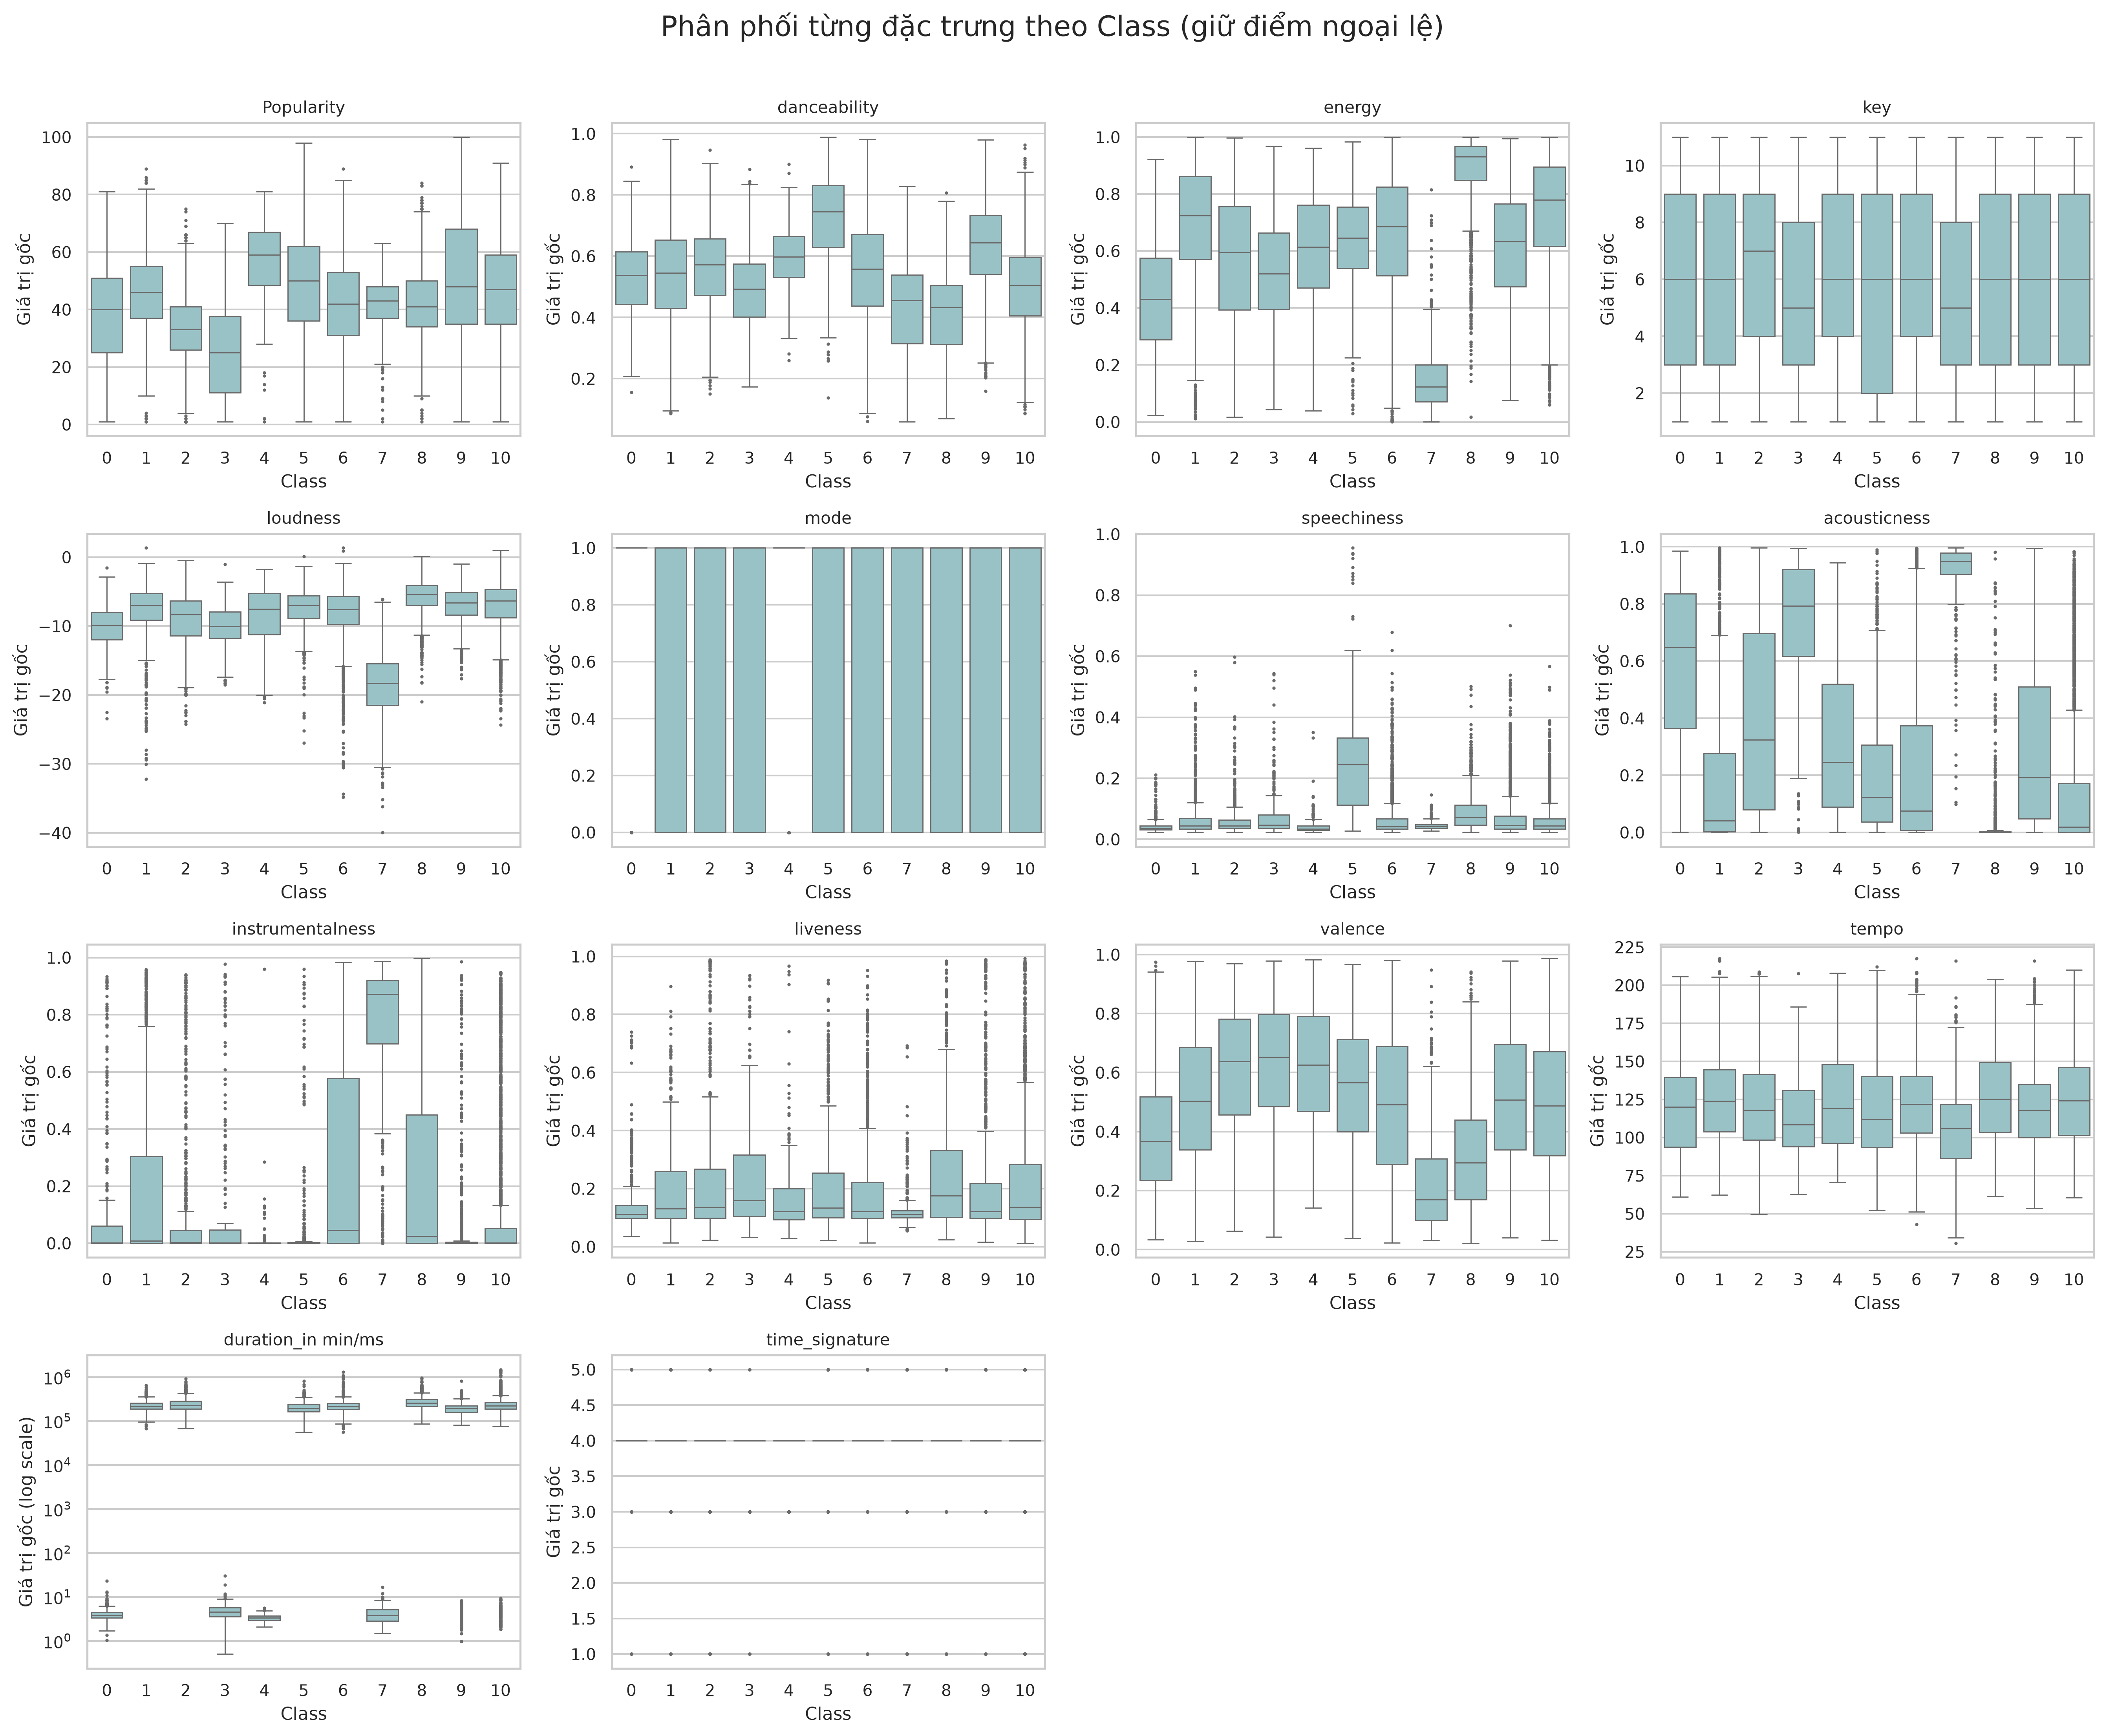

In [4]:
display(train[NUMERIC].describe(percentiles=[.01,.25,.5,.75,.99]).T.round(4))
outlier_rows = []
for c in NUMERIC:
    values = duration_seconds if c == DURATION else train[c]
    q1,q3 = values.quantile([.25,.75])
    iqr = q3-q1
    count = int(((values < q1-1.5*iqr) | (values > q3+1.5*iqr)).sum()) if iqr > 0 else 0
    outlier_rows.append({"feature": "duration_seconds (giả định)" if c == DURATION else c,
                         "min":float(values.min()), "max":float(values.max()),
                         "skew":float(values.skew()), "iqr_outliers":count,
                         "iqr_outliers_pct":count/values.notna().sum()*100})
outliers = pd.DataFrame(outlier_rows)
display(outliers.round(3))
fig, axes = plt.subplots(4, 4, figsize=(18, 15))
for ax,c in zip(axes.flat, NUMERIC):
    sns.boxplot(data=train, x="Class", y=c, ax=ax, color="#91c8cf", fliersize=1, linewidth=.7)
    if c == DURATION: ax.set_yscale("log")
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("Class")
    ax.set_ylabel("Giá trị gốc" + (" (log scale)" if c == DURATION else ""))
for ax in axes.flat[len(NUMERIC):]: ax.set_visible(False)
fig.suptitle("Phân phối từng đặc trưng theo Class (giữ điểm ngoại lệ)", fontsize=17)
fig.tight_layout(rect=(0,0,1,.97))
save_figure(fig, "B_03_feature_distributions.png")


## 4. Dữ liệu thiếu theo lớp và giả thuyết về key/Popularity
So sánh tỷ lệ thiếu train/test và theo từng Class. Với `key`, kiểm tra giá trị 0
có xuất hiện không chỉ là dấu hiệu; không đủ bằng chứng gán mọi NaN thành nốt C.
Với `Popularity`, so sánh lớp, đơn vị duration, nghệ sĩ, và trung vị các biến khác
giữa nhóm thiếu/không thiếu. Khác biệt mô tả không chứng minh cơ chế gây thiếu.


,train_n,train_pct,test_n,test_pct
instrumentalness,3541,24.597,836,23.222
key,1609,11.177,405,11.250
Popularity,333,2.313,95,2.639
danceability,0,0.000,0,0.000
loudness,0,0.000,0,0.000
energy,0,0.000,0,0.000
mode,0,0.000,0,0.000
speechiness,0,0.000,0,0.000
acousticness,0,0.000,0,0.000
liveness,0,0.000,0,0.000


,instrumentalness,key,Popularity
Class,,,
0,24.20,10.60,12.00
1,12.75,11.02,1.91
2,10.81,15.32,1.08
3,24.22,8.39,3.73
4,53.55,11.29,6.13
5,61.37,7.26,1.38
6,10.78,11.31,1.64
7,0.22,15.84,4.12
8,8.50,8.63,1.62


{'observed_values': [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0],
 'zero_train': 0,
 'zero_test': 0}

,energy,loudness,acousticness,instrumentalness,tempo,duration_seconds,duration_is_min
Popularity,,,,,,,
Popularity có giá trị,0.700,-7.010,0.0801,0.0040,120.068,219.998,0.0
Popularity thiếu,0.654,-7.261,0.1440,0.0022,119.510,210.860,0.0


Artist Name
Westlife             24
Britney Spears        7
The Beatles           7
Ronnie Milsap         6
Simon & Garfunkel     3
POORSTACY             3
Shungudzo             3
The Killers           3
INXS                  3
Atlas Genius          2
Meg Ward              2
Ayron Jones           2
Name: n_missing_popularity, dtype: int64

duration <30,False,True
Popularity thiếu,,
False,0.863614,0.136386
True,0.528529,0.471471


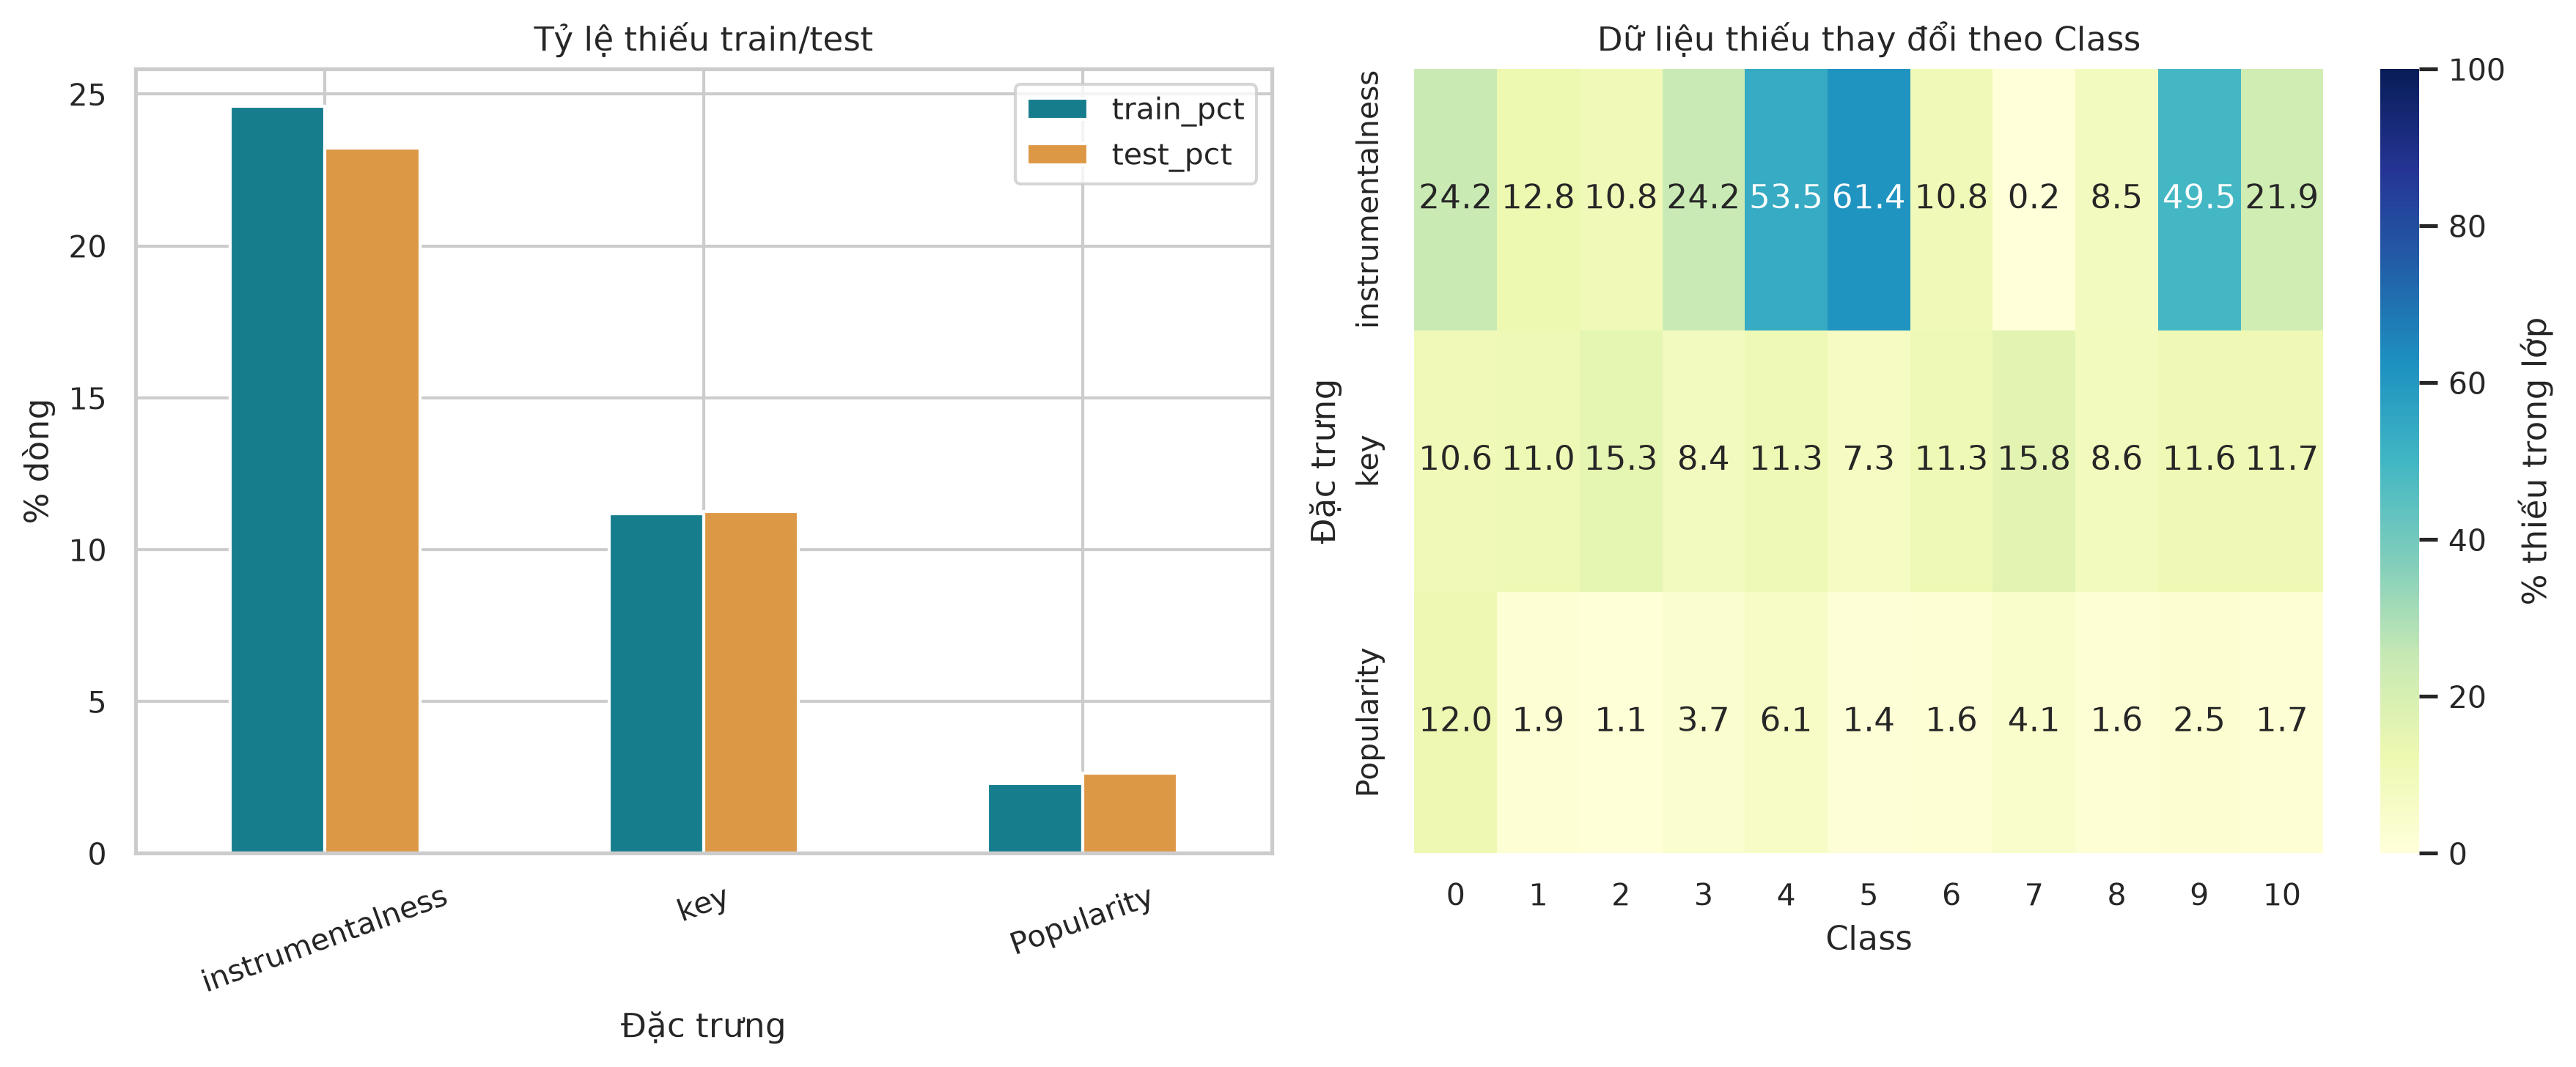

In [5]:
missing_table = pd.DataFrame({"train_n":train[NUMERIC].isna().sum(),
                              "train_pct":train[NUMERIC].isna().mean()*100,
                              "test_n":test[NUMERIC].isna().sum(),
                              "test_pct":test[NUMERIC].isna().mean()*100}).sort_values("train_pct", ascending=False)
missing_cols = missing_table.index[(missing_table.train_n + missing_table.test_n)>0].tolist()
missing_by_class = train[missing_cols].isna().groupby(train.Class).mean()*100
display(missing_table.round(3))
display(missing_by_class.round(2))
key_summary = {"observed_values": sorted(train.key.dropna().unique().tolist()),
               "zero_train": int(train.key.eq(0).sum()), "zero_test":int(test.key.eq(0).sum())}
display(key_summary)
pop_missing = train.Popularity.isna()
pop_profile = train.assign(duration_seconds=duration_seconds, duration_is_min=duration_minutes).groupby(pop_missing)[
    ["energy","loudness","acousticness","instrumentalness","tempo","duration_seconds","duration_is_min"]].median()
pop_profile.index = pop_profile.index.map({False:"Popularity có giá trị",True:"Popularity thiếu"})
display(pop_profile.round(4))
display(train.loc[pop_missing,"Artist Name"].value_counts().head(12).rename("n_missing_popularity"))
display(pd.crosstab(pop_missing, duration_minutes, normalize="index").rename_axis(index="Popularity thiếu",columns="duration <30"))
fig, axes = plt.subplots(1,2,figsize=(12,5))
missing_table.loc[missing_cols,["train_pct","test_pct"]].plot.bar(ax=axes[0],color=["#167d8d","#dd9846"],rot=20)
axes[0].set(title="Tỷ lệ thiếu train/test", ylabel="% dòng", xlabel="Đặc trưng")
sns.heatmap(missing_by_class.T,annot=True,fmt=".1f",cmap="YlGnBu",vmin=0,vmax=100,ax=axes[1],cbar_kws={"label":"% thiếu trong lớp"})
axes[1].set(title="Dữ liệu thiếu thay đổi theo Class",xlabel="Class",ylabel="Đặc trưng")
fig.tight_layout()
save_figure(fig,"B_04_missingness.png")


## 5. Tương quan và các cặp đặc trưng
Spearman trên các biến số, pairwise non-missing, duration đổi sang giây theo giả thuyết
ở mục 2. Không đưa Id hoặc Class vào ma trận đặc trưng; các mã như key/mode có hạn chế
khi diễn giải tương quan. Với ba biến energy, loudness, acousticness, bổ sung scatter.


,feature_1,feature_2,spearman
26,energy,loudness,0.7351
29,energy,acousticness,-0.7283
48,loudness,acousticness,-0.5604
21,danceability,valence,0.4379
28,energy,speechiness,0.3515
49,loudness,instrumentalness,-0.2396
23,danceability,duration_seconds,-0.2339
47,loudness,speechiness,0.2297
86,valence,duration_seconds,-0.2131
63,speechiness,acousticness,-0.2101


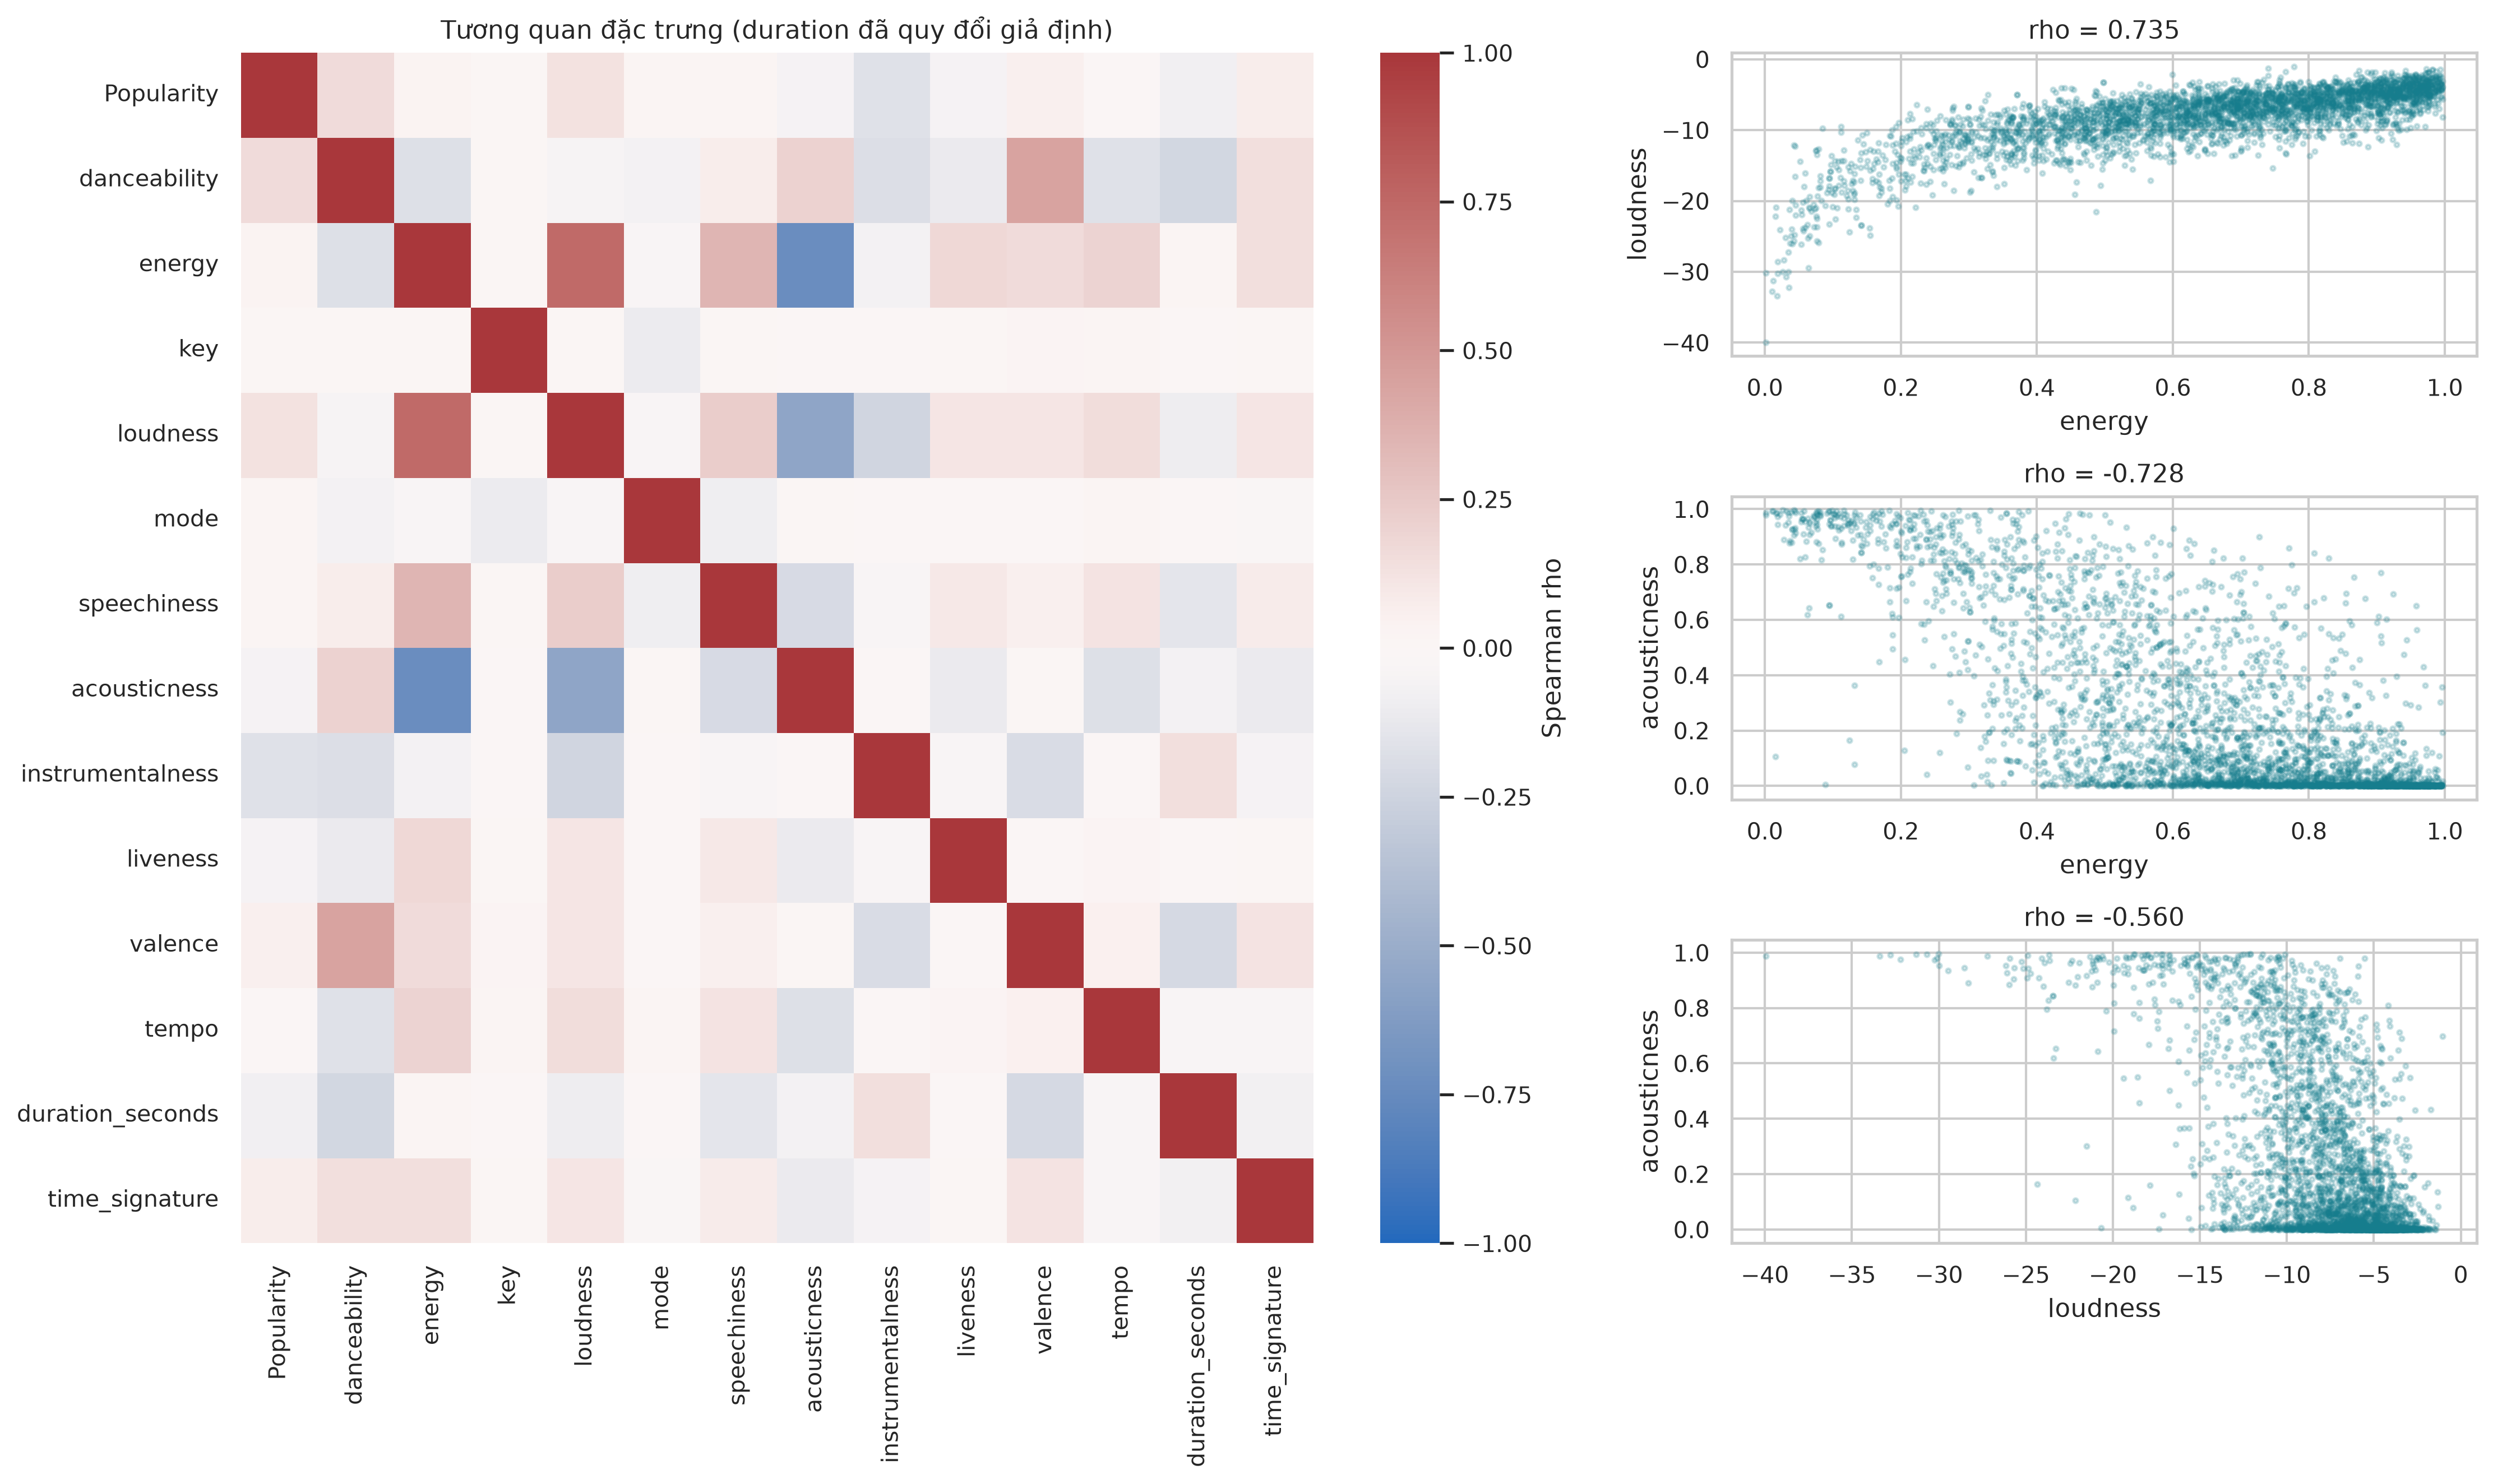

In [6]:
numeric_view = train[NUMERIC].copy()
numeric_view[DURATION] = duration_seconds
numeric_view = numeric_view.rename(columns={DURATION:"duration_seconds"})
corr = numeric_view.corr(method="spearman")
pairs = []
for i,c in enumerate(corr.columns):
    for d in corr.columns[i+1:]:
        pairs.append({"feature_1":c,"feature_2":d,"spearman":float(corr.loc[c,d])})
correlation_pairs = pd.DataFrame(pairs).sort_values("spearman",key=abs,ascending=False)
display(correlation_pairs.head(15).round(4))
fig = plt.figure(figsize=(15,9))
grid=fig.add_gridspec(3,2,width_ratios=[1.8,1])
ax=fig.add_subplot(grid[:,0])
sns.heatmap(corr,cmap="vlag",center=0,vmin=-1,vmax=1,ax=ax,cbar_kws={"label":"Spearman rho"})
ax.set_title("Tương quan đặc trưng (duration đã quy đổi giả định)")
sample_rows=train.sample(n=min(3500,len(train)),random_state=SEED)
for i,(x,y) in enumerate([("energy","loudness"),("energy","acousticness"),("loudness","acousticness")]):
    ax=fig.add_subplot(grid[i,1])
    ax.scatter(sample_rows[x],sample_rows[y],s=4,alpha=.2,color="#167d8d",rasterized=True)
    ax.set(xlabel=x,ylabel=y,title=f"rho = {corr.loc[x,y]:.3f}")
fig.tight_layout()
save_figure(fig,"B_05_correlations.png")


## 6. Nghệ sĩ, tên bài và độ phủ train/test
Đếm chính theo chuỗi nguyên gốc để khớp nhận xét của A; thêm kiểm tra strip/casefold.
Tách **tỷ lệ dòng test** có nghệ sĩ đã biết và **tỷ lệ nghệ sĩ duy nhất** đã biết.
Tên bài trùng có thể là cover/khác bản thu; kiểm tra mâu thuẫn nhãn trong train.
Không thể xác nhận nhãn của bài trùng ở test vì test không có Class.


unique_train_artists                         7913.000000
unique_test_artists                          2784.000000
seen_test_rows_n                             2296.000000
seen_test_rows_pct                             63.777778
seen_unique_test_artists_pct                   55.603448
seen_test_rows_normalized_pct                  63.777778
train_artists_multiple_classes               1375.000000
train_singleton_artists                      5289.000000
test_track_seen_n                             860.000000
test_track_seen_pct                            23.888889
test_artist_track_seen_n                      607.000000
test_artist_track_seen_pct                     16.861111
train_track_names_multiple_classes           1336.000000
train_artist_track_pairs_multiple_classes    1043.000000
dtype: float64

,n_tracks,n_classes
Artist Name,,
Backstreet Boys,58,1
Westlife,53,1
Britney Spears,47,1
Omer Adam,39,1
Eyal Golan,38,1
Shlomo Artzi,32,2
Dudu Aharon,29,1
Arik Einstein,29,1
Hadag Nahash,29,3


,n_tracks,n_classes
Artist Name,,
Shlomo Artzi,32,2
Hadag Nahash,29,3
The Rolling Stones,25,4
Yehudit Ravitz,23,2
AC/DC,22,2
Metallica,22,2
Dudu Tassa,22,3
U2,20,3
Led Zeppelin,19,6


Artist Name           Track Name                                
'68                   Bad Bite                                      [1, 6, 10]
100 gecs              money machine                                     [6, 9]
1000mods              Mirrors                                          [8, 10]
13th Floor Elevators  Slip Inside This House - Stereo LP Version       [2, 10]
347aidan              Dancing in My Room                                [5, 9]
4 Non Blondes         What's Up?                                       [9, 10]
? & The Mysterians    96 Tears                                         [6, 10]
A Perfect Circle      The Doomed                                       [8, 10]
AC/DC                 Back In Black                                    [8, 10]
                      Highway to Hell                                  [8, 10]
                      T.N.T.                                           [8, 10]
AJR                   Bang!                                       

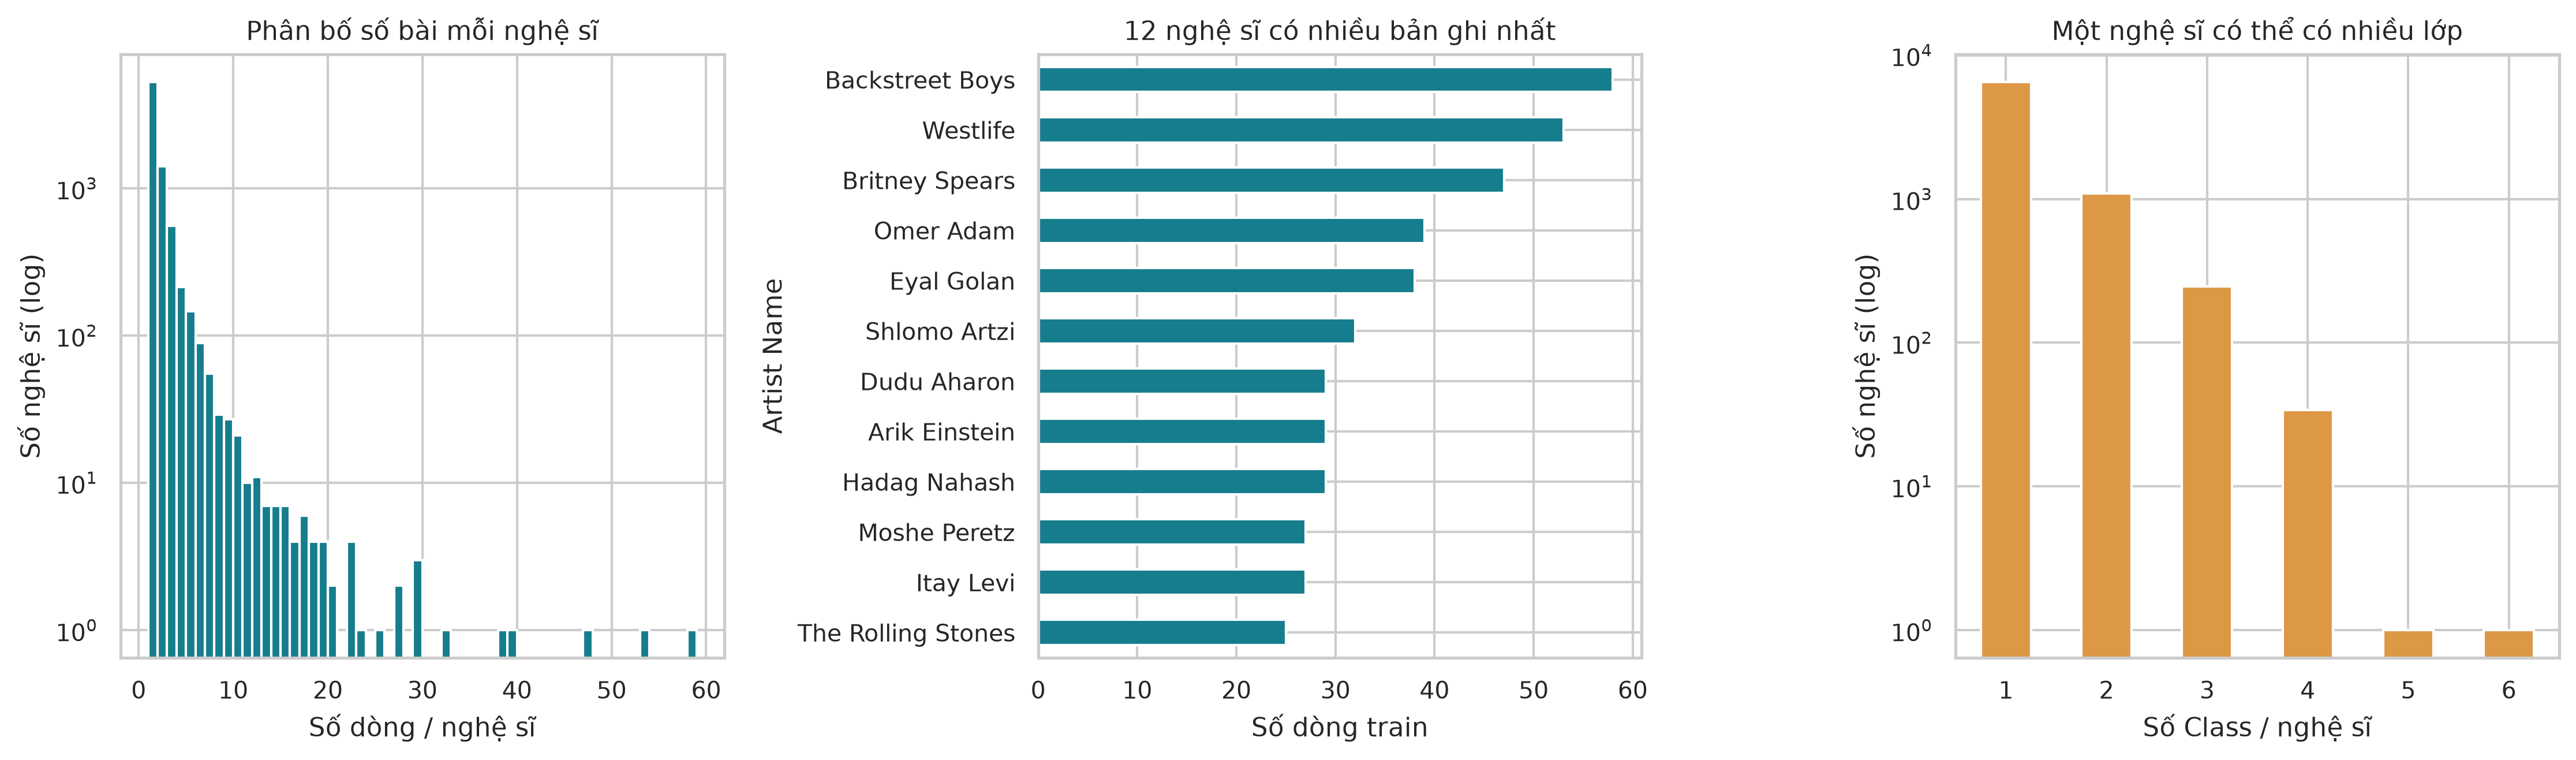

In [7]:
artist_sizes = train.groupby("Artist Name").size().sort_values(ascending=False)
artist_class_counts = train.groupby("Artist Name").Class.nunique()
track_label_counts = train.groupby("Track Name").Class.nunique()
pair_label_counts = train.groupby(["Artist Name","Track Name"]).Class.nunique()
test_artist_seen = test["Artist Name"].isin(set(train["Artist Name"]))
test_track_seen = test["Track Name"].isin(set(train["Track Name"]))
train_pairs=set(zip(train["Artist Name"],train["Track Name"]))
test_pair_seen=np.array([p in train_pairs for p in zip(test["Artist Name"],test["Track Name"])])
norm=lambda s:s.astype(str).str.strip().str.casefold()
artist_summary={
    "unique_train_artists":int(train["Artist Name"].nunique()),
    "unique_test_artists":int(test["Artist Name"].nunique()),
    "seen_test_rows_n":int(test_artist_seen.sum()), "seen_test_rows_pct":float(test_artist_seen.mean()*100),
    "seen_unique_test_artists_pct":len(set(test["Artist Name"]) & set(train["Artist Name"]))/test["Artist Name"].nunique()*100,
    "seen_test_rows_normalized_pct":float(norm(test["Artist Name"]).isin(set(norm(train["Artist Name"]))).mean()*100),
    "train_artists_multiple_classes":int(artist_class_counts.gt(1).sum()),
    "train_singleton_artists":int(artist_sizes.eq(1).sum()),
    "test_track_seen_n":int(test_track_seen.sum()),"test_track_seen_pct":float(test_track_seen.mean()*100),
    "test_artist_track_seen_n":int(test_pair_seen.sum()),"test_artist_track_seen_pct":float(test_pair_seen.mean()*100),
    "train_track_names_multiple_classes":int(track_label_counts.gt(1).sum()),
    "train_artist_track_pairs_multiple_classes":int(pair_label_counts.gt(1).sum()),
}
display(pd.Series(artist_summary))
artist_table=pd.DataFrame({"n_tracks":artist_sizes,"n_classes":artist_class_counts}).sort_values("n_tracks",ascending=False)
display(artist_table.head(15))
display(artist_table[artist_table.n_classes>1].head(15))
ambiguous_pairs=pair_label_counts[pair_label_counts>1].index
display(train.set_index(["Artist Name","Track Name"]).loc[list(ambiguous_pairs)].reset_index().groupby(["Artist Name","Track Name"]).Class.agg(lambda s:sorted(s.unique())).head(12) if len(ambiguous_pairs) else "Không có cặp artist/track đa nhãn")
fig,axes=plt.subplots(1,3,figsize=(15,4.5))
axes[0].hist(artist_sizes,bins=np.arange(1,artist_sizes.max()+2),color="#167d8d")
axes[0].set(xlabel="Số dòng / nghệ sĩ",ylabel="Số nghệ sĩ (log)",title="Phân bố số bài mỗi nghệ sĩ",yscale="log")
artist_table.head(12).n_tracks.iloc[::-1].plot.barh(ax=axes[1],color="#167d8d")
axes[1].set(xlabel="Số dòng train",ylabel="Artist Name",title="12 nghệ sĩ có nhiều bản ghi nhất")
artist_class_counts.value_counts().sort_index().plot.bar(ax=axes[2],color="#dd9846",rot=0)
axes[2].set(xlabel="Số Class / nghệ sĩ",ylabel="Số nghệ sĩ (log)",title="Một nghệ sĩ có thể có nhiều lớp",yscale="log")
fig.tight_layout()
save_figure(fig,"B_06_artists_tracks.png")


### Đối chiếu nhận xét “nghệ sĩ đã biết” bằng folds chung
Trong từng train fold, lấy Class phổ biến nhất của nghệ sĩ. Trường hợp hòa chọn
mã nhỏ nhất; nghệ sĩ chưa biết lấy lớp phổ biến nhất train fold. Đánh giá mô tả trên
validation fold, chỉ dùng nhãn train fold. Đây là kiểm chứng nhận xét của A, không
phải tuning/target encoding của C/D và không tạo submission. Không dùng test để tính accuracy.


In [8]:
artist_fold_rows=[]
all_known=[];all_correct=[]
for fold,(itr,ival) in enumerate(get_folds(train.Class.to_numpy()),start=1):
    fit=train.iloc[itr]; val=train.iloc[ival]
    counts=fit.groupby(["Artist Name","Class"]).size().rename("n").reset_index()
    majority=counts.sort_values(["Artist Name","n","Class"],ascending=[True,False,True]).drop_duplicates("Artist Name").set_index("Artist Name").Class
    mapped=val["Artist Name"].map(majority)
    known=mapped.notna().to_numpy()
    fallback=int(fit.Class.mode().iloc[0])
    prediction=mapped.fillna(fallback).to_numpy()
    correct=prediction==val.Class.to_numpy()
    all_known.extend(known.tolist());all_correct.extend(correct.tolist())
    artist_fold_rows.append({"fold":fold,"known_n":int(known.sum()),"val_n":len(val),
                             "known_coverage":float(known.mean()),
                             "accuracy_known":float(correct[known].mean()),
                             "accuracy_all_with_prior":float(correct.mean())})
known=np.array(all_known);correct=np.array(all_correct)
artist_cv={"coverage_known":float(known.mean()),"accuracy_known":float(correct[known].mean()),
           "accuracy_all_with_prior":float(correct.mean()),"folds":artist_fold_rows}
display(pd.DataFrame(artist_fold_rows).round(4))
display({k:v for k,v in artist_cv.items() if k!="folds"})


,fold,known_n,val_n,known_coverage,accuracy_known,accuracy_all_with_prior
0,1,1698,2880,0.5896,0.6207,0.4438
1,2,1694,2879,0.5884,0.6263,0.4491
2,3,1672,2879,0.5808,0.6220,0.4404
3,4,1673,2879,0.5811,0.6252,0.4595
4,5,1710,2879,0.5940,0.6211,0.4509


{'coverage_known': 0.5867602111697694,
 'accuracy_known': 0.6230614419320469,
 'accuracy_all_with_prior': 0.4487357599333148}

## 7. PCA: quan sát sự chồng lấn giữa các Class
Fit imputer median, StandardScaler và PCA **chỉ trên train**, không đưa text, Id hoặc
Class vào đặc trưng. Duration quy đổi theo giả thuyết ở mục 2. Key là mã rời rạc nên
PCA trên mã số chỉ mang tính khám phá. Không dùng embedding làm kết quả phân loại.
Ma trận láng giềng 15-NN trong 2D cho biết thành phần nhãn quanh từng lớp, phụ thuộc
mất cân bằng và mất thông tin khi chiếu; không thay thế confusion matrix mô hình.


,class_1,class_2,symmetric_neighbor_fraction
0,8,10,0.2489
1,6,10,0.2146
2,1,10,0.1945
3,5,9,0.1919
4,9,10,0.1748
5,2,10,0.1586
6,6,9,0.1389
7,4,10,0.1361
8,1,6,0.1284
9,0,10,0.1233


,PC1_loading,PC2_loading
Popularity,0.134,0.214
danceability,0.115,0.595
energy,0.511,-0.257
key,0.017,0.015
loudness,0.509,-0.117
mode,-0.033,-0.046
speechiness,0.141,0.178
acousticness,-0.468,0.219
instrumentalness,-0.268,-0.256
liveness,0.120,-0.190


Explained variance: [0.20181144 0.12935342] total 0.33116485938065476


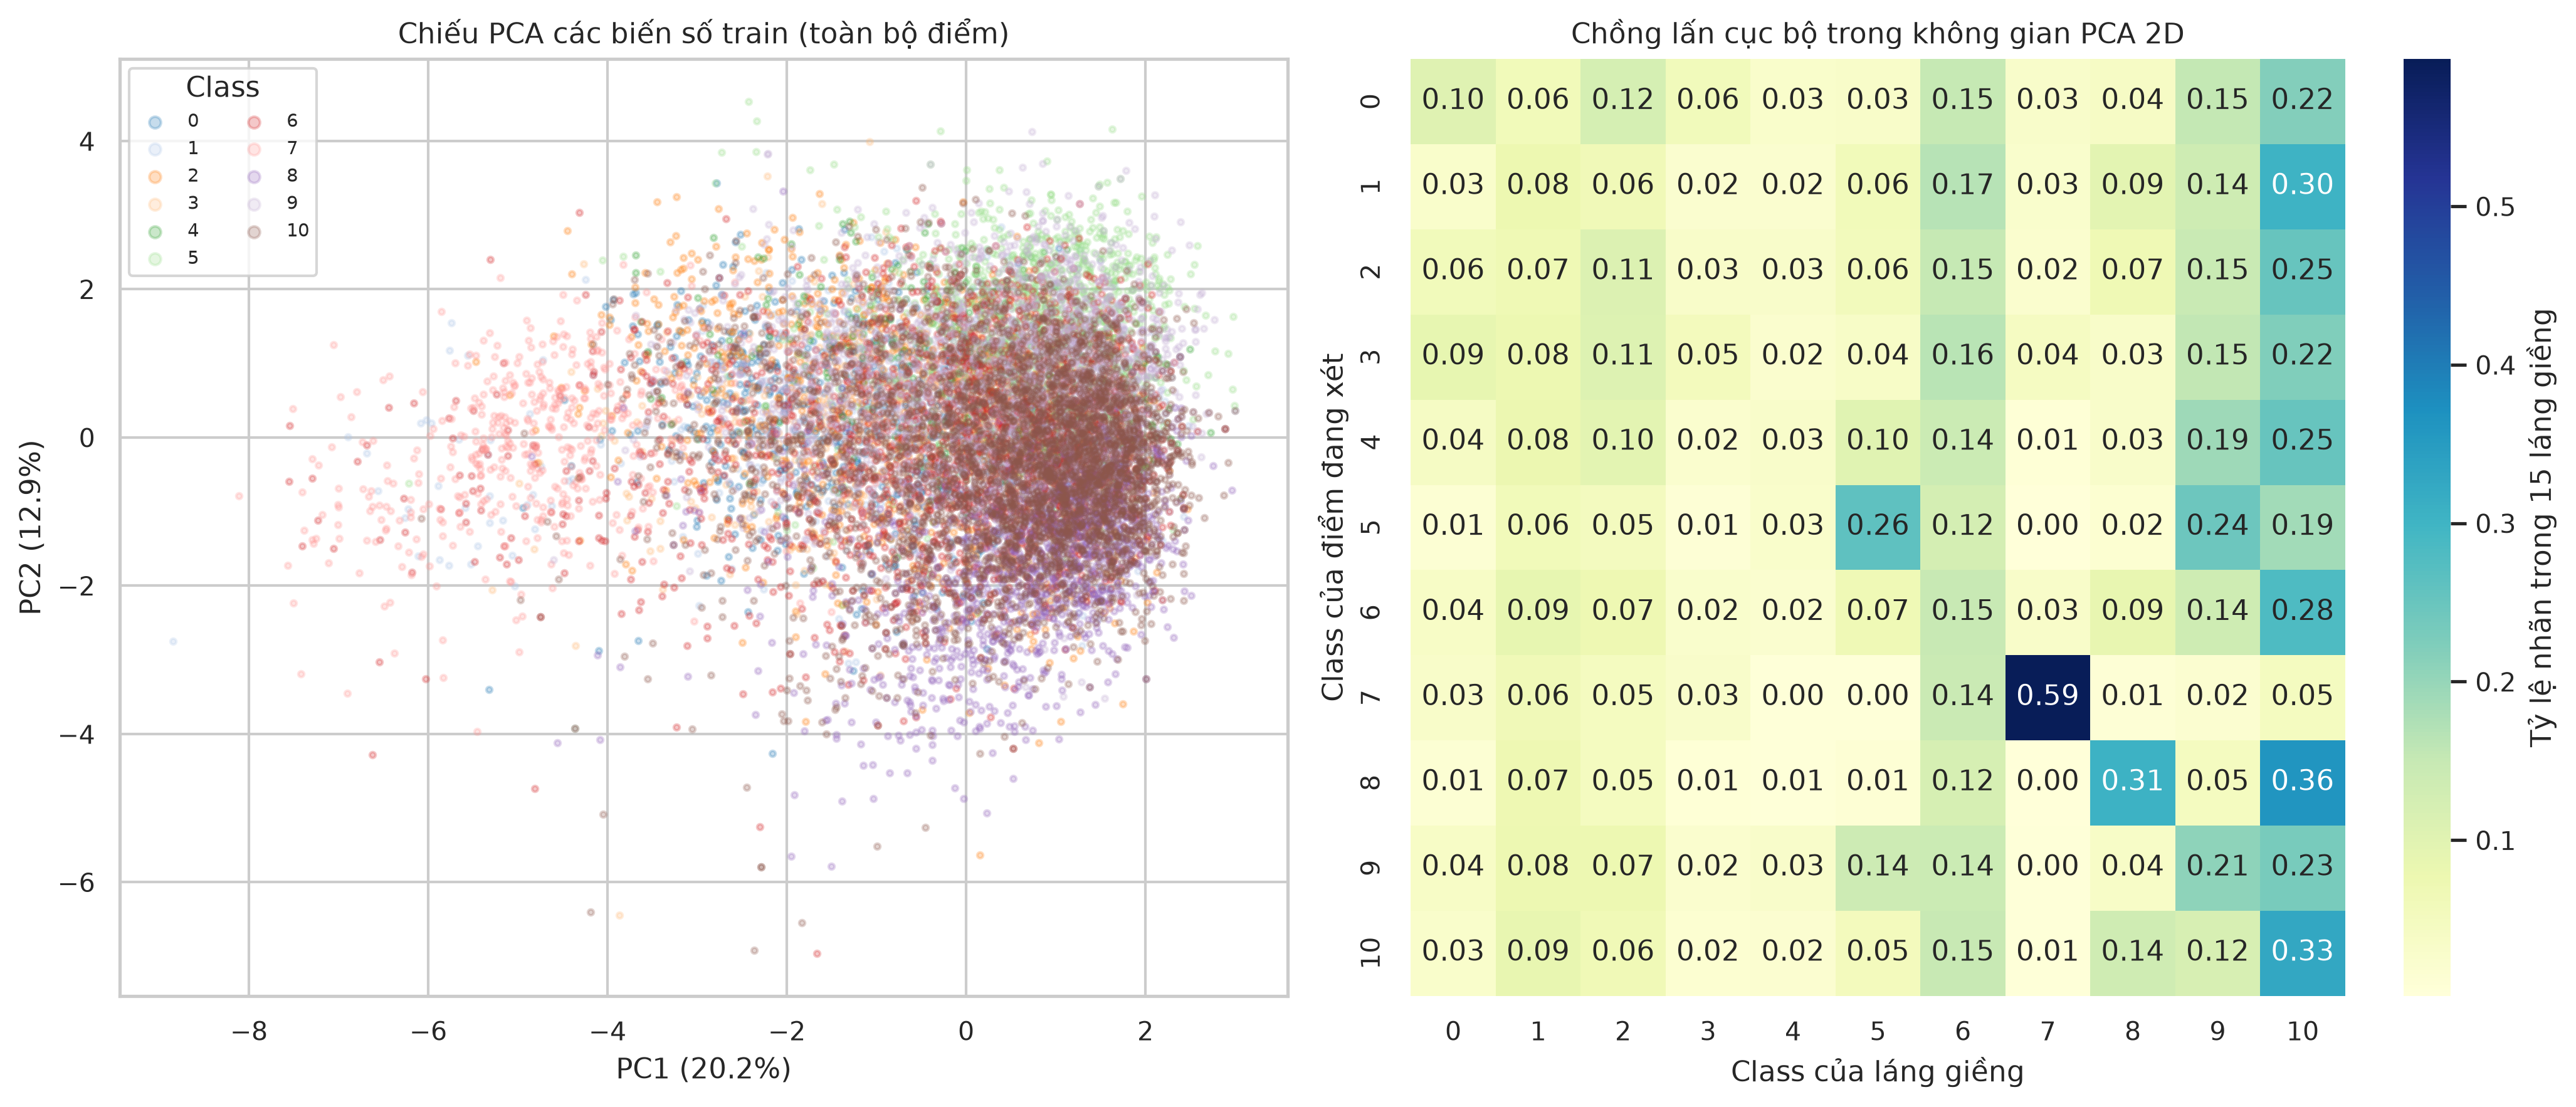

In [9]:
imputer=SimpleImputer(strategy="median")
scaler=StandardScaler()
scaled=scaler.fit_transform(imputer.fit_transform(numeric_view))
pca=PCA(n_components=2,random_state=SEED)
coordinates=pca.fit_transform(scaled)
labels=train.Class.to_numpy()
assert coordinates.shape==(len(train),2) and np.isfinite(coordinates).all()
neighbor_candidates=NearestNeighbors(n_neighbors=16).fit(coordinates).kneighbors(coordinates,return_distance=False)
neighbors=np.array([row[row != i][:15] for i,row in enumerate(neighbor_candidates)])
assert not np.any(neighbors == np.arange(len(train))[:, None])
mix=np.zeros((11,11))
for c in CLASSES:
    neighbor_labels=labels[neighbors[labels==c]].ravel()
    mix[c]=np.bincount(neighbor_labels,minlength=11)/len(neighbor_labels)
overlap_pairs=sorted([{"class_1":a,"class_2":b,"symmetric_neighbor_fraction":float((mix[a,b]+mix[b,a])/2)}
                      for a in CLASSES for b in CLASSES if a<b],key=lambda x:-x["symmetric_neighbor_fraction"])
display(pd.DataFrame(overlap_pairs[:10]).round(4))
display(pd.DataFrame(pca.components_.T,index=numeric_view.columns,columns=["PC1_loading","PC2_loading"]).round(3))
print("Explained variance:",pca.explained_variance_ratio_,"total",pca.explained_variance_ratio_.sum())
fig,axes=plt.subplots(1,2,figsize=(14,6))
for c in CLASSES:
    mask=labels==c
    axes[0].scatter(coordinates[mask,0],coordinates[mask,1],s=5,alpha=.25,color=PALETTE[c],label=str(c),rasterized=True)
axes[0].set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})",ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})",title="Chiếu PCA các biến số train (toàn bộ điểm)")
axes[0].legend(title="Class",fontsize=7,markerscale=2,ncol=2)
sns.heatmap(mix,annot=True,fmt=".2f",cmap="YlGnBu",ax=axes[1],xticklabels=CLASSES,yticklabels=CLASSES,cbar_kws={"label":"Tỷ lệ nhãn trong 15 láng giềng"})
axes[1].set(xlabel="Class của láng giềng",ylabel="Class của điểm đang xét",title="Chồng lấn cục bộ trong không gian PCA 2D")
fig.tight_layout()
save_figure(fig,"B_07_pca_overlap.png")


## 8. Bảng kiểm chứng bảy nhận xét của A
So sánh có ghi định nghĩa/mẫu số. Số nào khác sẽ được ghi trong bản bàn giao cho C;
không sửa số liệu A hay sửa file của thành viên khác.


In [10]:
checks = [
    {"finding":"1. Mất cân bằng lớp", "measured":f"Class 10: {class_counts[10]}; 6: {class_counts[6]}; 9: {class_counts[9]}; 4: {class_counts[4]}; 3: {class_counts[3]}","note":"Khớp số đếm A; B không chạy thí nghiệm class_weight."},
    {"finding":"2. Duration hai thang đo","measured":f"Train <30: {duration_records['train']['n_lt30']} ({duration_records['train']['pct_lt30']:.2f}%); ngưỡng khác nhau: {duration_records['train']['threshold_disagreements']} train / {duration_records['test']['threshold_disagreements']} test","note":"Xem bảng theo lớp; đơn vị phút/ms là giả thuyết theo dữ liệu."},
    {"finding":"3. Thiếu có quy luật","measured":"; ".join(f"{c}: {missing_table.loc[c,'train_pct']:.2f}%" for c in missing_cols),"note":"Mức thiếu khác theo Class; không chứng minh nguyên nhân."},
    {"finding":"4. Nghệ sĩ đã biết","measured":f"Test rows seen {artist_summary['seen_test_rows_pct']:.2f}%; CV coverage {artist_cv['coverage_known']:.2%}, accuracy known {artist_cv['accuracy_known']:.2%}","note":"A ghi 62,8%; B đo 62,31% với cùng folds và chọn mã nhỏ nhất khi hòa. Cần đối chiếu quy tắc; không sửa số liệu A."},
    {"finding":"5. Tên bài trùng train/test","measured":f"{artist_summary['test_track_seen_n']}/{len(test)} dòng test ({artist_summary['test_track_seen_pct']:.2f}%)","note":"Không xác minh nhãn test; tên trùng không bảo đảm cùng bản thu."},
    {"finding":"6. Key và trùng dòng","measured":f"Key zero train/test {key_summary['zero_train']}/{key_summary['zero_test']}; duplicates {duplicates}","note":"Chưa đủ bằng chứng để thay key NaN bằng 0."},
    {"finding":"7. Id tách biệt","measured":f"Train {int(train.Id.min())}–{int(train.Id.max())}; test {int(test.Id.min())}–{int(test.Id.max())}; intersection {len(set(train.Id)&set(test.Id))}","note":"Giữ ID để xuất bài, loại khỏi đặc trưng."},
]
display(pd.DataFrame(checks))


,finding,measured,note
0,1. Mất cân bằng lớp,Class 10: 3959; 6: 2069; 9: 2019; 4: 310; 3: 322,Khớp số đếm A; B không chạy thí nghiệm class_w...
1,2. Duration hai thang đo,Train <30: 2075 (14.41%); ngưỡng khác nhau: 0 ...,Xem bảng theo lớp; đơn vị phút/ms là giả thuyế...
2,3. Thiếu có quy luật,instrumentalness: 24.60%; key: 11.18%; Popular...,Mức thiếu khác theo Class; không chứng minh ng...
3,4. Nghệ sĩ đã biết,"Test rows seen 63.78%; CV coverage 58.68%, acc...","A ghi 62,8%; B đo 62,31% với cùng folds và chọ..."
4,5. Tên bài trùng train/test,860/3600 dòng test (23.89%),Không xác minh nhãn test; tên trùng không bảo ...
5,6. Key và trùng dòng,Key zero train/test 0/0; duplicates {'train_fu...,Chưa đủ bằng chứng để thay key NaN bằng 0.
6,7. Id tách biệt,Train 1–14396; test 14397–17996; intersection 0,"Giữ ID để xuất bài, loại khỏi đặc trưng."


## 9. Xuất bản bàn giao C, mục 3 của paper và bằng chứng
Chưa đánh dấu C đã xác nhận nhận bàn giao. Nội dung sinh từ số đo ở trên và có
thể cập nhật bằng Restart & Run All. Các kết quả CV/leaderboard thuộc A/D/E
không được trình bày thành kết quả do B chạy.


In [11]:
def pct(x): return f"{x:.2f}%"
def rawhashes_unchanged():
    return all(hashlib.sha256((ROOT/"data"/n).read_bytes()).hexdigest()==h for n,h in INPUT_HASHES.items())
assert rawhashes_unchanged(), "Dữ liệu gốc đã thay đổi"
summary={
    "author":"Nguyễn Minh Triết (B), 3124411320", "created_utc":datetime.now(timezone.utc).isoformat(),
    "source":"Kaggle ZIP supplied by user", "input_sha256":INPUT_HASHES,
    "python":platform.python_version(), "packages":{p:version(p) for p in ["numpy","pandas","matplotlib","seaborn","scikit-learn","nbformat","nbclient","ipykernel","notebook"]},
    "seed":SEED, "n_folds":N_FOLDS, "shape_train":list(train.shape),"shape_test":list(test.shape),
    "class_counts":{str(k):int(v) for k,v in class_counts.items()},
    "duplicates":duplicates,"duration":duration_records,
    "duration_by_class":json.loads(duration_by_class.reset_index().to_json(orient="records")),
    "missing":json.loads(missing_table.reset_index(names="feature").to_json(orient="records")),
    "missing_by_class":json.loads(missing_by_class.reset_index().to_json(orient="records")),
    "key":key_summary,"artist_track":artist_summary,"artist_fold_check":artist_cv,
    "outliers":json.loads(outliers.to_json(orient="records")),
    "correlations":json.loads(correlation_pairs.head(15).to_json(orient="records")),
    "pca_explained_variance":pca.explained_variance_ratio_.tolist(),"pca_overlap_pairs":overlap_pairs[:10],
    "handoff_C_confirmed":False,
}
display(summary)  # Evidence, versions and raw hashes are retained in notebook output.
req='''# EDA B: Python 3.12.10. Dependencies for Restart & Run All.\n'''+"\\n".join(f"{p}=={v}" for p,v in summary["packages"].items())+"\\n"
(ROOT/"code/requirements_B.txt").write_text(req.replace("\\n","\n"),encoding="utf-8")
missing_text=", ".join(f"{c} {missing_table.loc[c,'train_pct']:.2f}%" for c in missing_cols)
gap_text=f"{duration_records['train']['threshold_disagreements']} dòng train / {duration_records['test']['threshold_disagreements']} dòng test"
top_overlap=", ".join(f"{d['class_1']}–{d['class_2']}" for d in overlap_pairs[:3])
findings=f'''# Bàn giao EDA từ B cho C
Nguyễn Minh Triết · 3124411320. **Trạng thái: đã chuẩn bị, chờ C xác nhận.**
Nguồn: ZIP Kaggle người dùng cung cấp; bằng chứng: `code/01_eda_B.ipynb` (bảng kiểm chứng và số liệu ở mục 8–9).

| Phát hiện đo trên dữ liệu | Đề xuất để C thử trong ablation |
|---|---|
| Train 14.396 × 18, test 3.600 × 17; 11 lớp. Class 10: 3.959, Class 4: 310; lệch {class_counts.max()/class_counts.min():.2f} lần. | Giữ folds phân tầng seed 42. Tối ưu accuracy theo quy ước nhóm, báo thêm macro-F1; B chưa kiểm chứng thí nghiệm class_weight. |
| Duration <30: {duration_records['train']['n_lt30']} dòng ({duration_records['train']['pct_lt30']:.2f}%); giá trị nhỏ {duration_records['train']['small_range'][0]:.3f}–{duration_records['train']['small_range'][1]:.3f}; nhóm lớn từ {duration_records['train']['large_range'][0]:.0f}. Ngưỡng <30 và <1000 khác ở {gap_text}. | Giả thuyết nhóm nhỏ là phút, nhóm lớn ms: quy về giây/phút và giữ cờ nguồn. Hiện `features.py` dùng <1000, cần thống nhất ngưỡng theo kết quả này. Không coi cờ là đặc tính âm nhạc phổ quát. |
| Thiếu train: {missing_text}; thay đổi theo Class. Key không có 0 trong train/test. | Giữ missing flags; imputation/scaling chỉ fit train fold. Không tự thay mọi key NaN thành 0 khi chưa có bằng chứng từ nguồn. So NaN nguyên với imputer trên mô hình hỗ trợ. |
| Loudness {train.loudness.min():.3f} đến {train.loudness.max():.3f}; tempo {train.tempo.min():.3f} đến {train.tempo.max():.3f}. Bảng skew/IQR trong notebook. | Thử log1p cho biến lệch không âm và tương tác theo phân công. Cắt đuôi là lựa chọn phải ablation; không tự xóa cực trị nếu chưa xác minh lỗi. Key/mode/time_signature là mã rời rạc. |
| {artist_summary['seen_test_rows_n']}/3.600 dòng test ({artist_summary['seen_test_rows_pct']:.2f}%) có artist đã thấy; {artist_summary['train_artists_multiple_classes']} nghệ sĩ train có nhiều lớp. Kiểm tra folds: coverage {artist_cv['coverage_known']:.2%}, đúng {artist_cv['accuracy_known']:.2%} trên nhóm biết artist. | Artist hữu ích nhưng có đa nhãn. Encoding dùng nhãn cần fit trong từng outer fold và OOF bên trong train; nghệ sĩ lạ dùng prior. Kiểm tra grouped-by-artist bổ sung nếu mục tiêu là nghệ sĩ mới. |
| {artist_summary['test_track_seen_n']} dòng test ({artist_summary['test_track_seen_pct']:.2f}%) trùng tên track; {artist_summary['test_artist_track_seen_n']} dòng trùng cả artist/track; {artist_summary['train_artist_track_pairs_multiple_classes']} cặp artist/track train có nhiều nhãn. | Không gán nhãn theo tên trùng; test không có Class để xác minh. Tách exact match khỏi chuẩn hóa chuỗi và bản thu/cover. |

Spearman: energy–loudness {corr.loc['energy','loudness']:.3f}, energy–acousticness {corr.loc['energy','acousticness']:.3f}. PCA 2D giữ {pca.explained_variance_ratio_.sum():.1%} phương sai; các cặp có trộn láng giềng cao gồm {top_overlap}, chỉ là dấu hiệu trên phép chiếu, chưa là lỗi mô hình.
Đối chiếu A: độ đúng nghệ sĩ đã biết 62,31% so với mốc 62,8%; cần kiểm tra quy tắc hòa/định nghĩa trước khi kết luận nguyên nhân khác biệt. Popularity thiếu ở 333 dòng (Class 0: 12,0%); nhóm thiếu có trung vị acousticness 0,144 so với 0,0801.
ID train/test không giao nhau; trùng dòng train bỏ Id: {duplicates['train_without_id']}. Giữ dữ liệu gốc, không dùng Id làm feature. **C xác nhận nhận bàn giao: chưa có.**
'''
(ROOT/"eda_findings.md").write_text(findings,encoding="utf-8")
count_rows="\n".join(f"| {c} | {class_counts[c]} | {100*class_counts[c]/len(train):.2f}% |" for c in CLASSES)
paper=f'''# 3. Dataset & Exploratory Data Analysis

**Phần B — Nguyễn Minh Triết, 3124411320.** Phân tích trên bộ dữ liệu Kaggle do người dùng cung cấp; không dùng dữ liệu bên ngoài. Số liệu do notebook `code/01_eda_B.ipynb` tính trực tiếp; ngày chạy, phiên bản thư viện và SHA-256 lưu ở mục 9 của notebook.

## 3.1. Nguồn và cấu trúc dữ liệu

Cuộc thi [Music Genre Classification](https://www.kaggle.com/competitions/shai-music-genre-classification/data) cung cấp dữ liệu dạng bảng, không có tín hiệu âm thanh. Train gồm **14.396 dòng × 18 cột**, test **3.600 dòng × 17 cột** và sample submission **3.600 dòng × 2 cột** (`Id`, `Class`). Sau khi bỏ Id và nhãn, có 16 đầu vào: hai chuỗi Artist Name, Track Name và 14 biến số/mã rời rạc (Popularity, danceability, energy, key, loudness, mode, speechiness, acousticness, instrumentalness, liveness, valence, tempo, duration_in min/ms, time_signature). Một dòng biểu diễn một bản ghi bài hát; cùng artist/track không bảo đảm cùng bản thu.

Nhãn Class có 11 mã 0–10. Chưa có ánh xạ thể loại được xác minh nên giữ nguyên mã thay vì tự đặt tên. ID duy nhất trong mỗi tập, không giao nhau giữa train và test; thứ tự ID sample submission khớp test. Train có {duplicates['train_full']} dòng trùng khi tính cả ID và {duplicates['train_without_id']} dòng trùng khi bỏ ID, {duplicates['train_without_id_label']} dòng trùng phần đầu vào khi bỏ cả ID/nhãn. Test bỏ ID có {duplicates['test_without_id']} dòng trùng. ID chỉ phục vụ truy vết/xuất bài.

## 3.2. Phân bố lớp

Hình 1 cho thấy mất cân bằng: Class 10 có {class_counts[10]:,} mẫu ({100*class_counts[10]/len(train):.2f}%), Class 4 có {class_counts[4]} mẫu ({100*class_counts[4]/len(train):.2f}%), chênh {class_counts.max()/class_counts.min():.2f} lần. Nhóm dùng phân tầng theo nhãn, seed 42 và 5 folds qua `common.py`. Accuracy là tiêu chí chính theo quy ước cuộc thi của nhóm; macro-F1 cần được báo bổ sung để theo dõi các lớp nhỏ. EDA này không chạy ablation class_weight và không tự khẳng định cân bằng lớp làm tốt/xấu hơn.

| Class | Số mẫu | Tỷ lệ |
|---|---:|---:|
{count_rows}

![Hình 1. Phân bố lớp](figures/B_01_class_distribution.png)

## 3.3. Thang đo duration và phân phối đặc trưng

Duration có hai cụm thang đo. Có {duration_records['train']['n_lt30']} dòng train ({duration_records['train']['pct_lt30']:.2f}%) dưới 30, nằm trong khoảng {duration_records['train']['small_range'][0]:.3f}–{duration_records['train']['small_range'][1]:.3f}; phần còn lại bắt đầu từ {duration_records['train']['large_range'][0]:.0f}. Theo giả thuyết của A, nhóm nhỏ là phút và nhóm lớn là mili giây. B quy đổi giả định về giây để mô tả, đồng thời giữ cờ duration <30. Đây là diễn giải từ thang đo, chưa có metadata xác nhận đơn vị từng dòng. Ngưỡng <30 trong phân công và <1000 trong features.py khác nhau ở {gap_text}; cần thống nhất trước khi C chốt pipeline. Bảng tỷ lệ theo từng lớp trong notebook kiểm chứng nhận xét các Class 0,3,4,7 có duration nhóm nhỏ.

Sự liên hệ mạnh giữa cờ đơn vị và Class có thể là dấu vết nguồn thu thập. C cần đánh giá ablation cờ này và nêu giới hạn khái quát hóa sang dữ liệu có đơn vị thống nhất. Hình 2 trình bày thang đo gốc, tỷ lệ cờ theo lớp, energy và duration sau quy đổi giả định.

![Hình 2. Đặc trưng và hiện tượng đơn vị duration](figures/B_02_duration_and_features.png)

Phân phối đầy đủ của 14 biến nằm ở mục 3 trong notebook. Loudness nằm trong [{train.loudness.min():.3f}, {train.loudness.max():.3f}], tempo [{train.tempo.min():.3f}, {train.tempo.max():.3f}]. Các cực trị thống kê theo IQR không tự chứng minh lỗi dữ liệu; B không xóa hoặc winsorize. Các biến không âm lệch có thể được C thử log1p, trong khi key/mode/time_signature cần được xem như mã hoặc biến rời rạc phù hợp.

## 3.4. Dữ liệu thiếu

Các biến thiếu trong train gồm {missing_text}. Hình dữ liệu thiếu tại mục 4 trong notebook so sánh train/test và tỷ lệ thiếu theo Class; bảng trung vị nhóm thiếu/không thiếu Popularity trong notebook cho phép kiểm tra liệu nhóm thiếu có đặc điểm khác. Popularity thiếu ở 333 dòng; tỷ lệ thiếu là 12,0% ở Class 0 và 6,13% ở Class 4. Nhóm thiếu có trung vị acousticness 0,144 so với 0,0801 ở nhóm có giá trị, energy 0,654 so với 0,700. Các khác biệt không chứng minh cơ chế gây thiếu hoặc chứng minh giá trị 0 đã biến thành NaN.

Key quan sát có các giá trị {key_summary['observed_values']}; số giá trị 0 trong train/test lần lượt {key_summary['zero_train']}/{key_summary['zero_test']}. Thiếu giá trị 0 là dấu hiệu phù hợp với một giả thuyết về mã nốt C, nhưng không đủ xác định mọi NaN là nốt C. C nên giữ missing flags và so sánh imputation/giữ NaN trong folds, chưa tự gán tất cả NaN thành 0. Thống kê fit như median/scaler phải học trên train fold; các thống kê EDA toàn train chỉ phục vụ mô tả.

## 3.5. Tương quan và quan hệ nghệ sĩ/bài hát

Spearman energy–loudness = {corr.loc['energy','loudness']:.3f}, energy–acousticness = {corr.loc['energy','acousticness']:.3f}, loudness–acousticness = {corr.loc['loudness','acousticness']:.3f} (pairwise non-missing). Ma trận bỏ Id/Class, duration quy đổi giả định. Tương quan giữa các đặc trưng cần được cân nhắc khi tạo tương tác và diễn giải importance; không mặc định loại biến chỉ vì có tương quan.

Train có {artist_summary['unique_train_artists']} nghệ sĩ duy nhất, {artist_summary['train_singleton_artists']} chỉ có một dòng và {artist_summary['train_artists_multiple_classes']} xuất hiện ở nhiều Class. Có {artist_summary['seen_test_rows_n']}/3.600 dòng test ({artist_summary['seen_test_rows_pct']:.2f}%) có nghệ sĩ xuất hiện trong train theo chuỗi nguyên gốc, trong khi tỷ lệ trên nghệ sĩ test duy nhất là {artist_summary['seen_unique_test_artists_pct']:.2f}%. Hai mẫu số này cần phân biệt. Kiểm chứng theo 5 folds chung: {artist_cv['coverage_known']:.2%} mẫu validation biết nghệ sĩ từ train fold; quy tắc Class phổ biến của nghệ sĩ đúng {artist_cv['accuracy_known']:.2%} trên riêng nhóm đó. Khi thêm fallback lớp phổ biến train fold cho nghệ sĩ lạ, accuracy toàn bộ là {artist_cv['accuracy_all_with_prior']:.4f}. Mốc A ghi 62,8% trên nhóm biết artist, chênh khoảng 0,49 điểm phần trăm so với B; cần đối chiếu quy tắc hòa/định nghĩa nhóm trước khi quy nguyên nhân. Đây là kiểm chứng mô tả của B, không phải mô hình cuối/tuning của D. Đặc trưng dùng nhãn nghệ sĩ cần cross-fit bên trong pipeline để tránh leakage; đánh giá nghệ sĩ mới cần cân nhắc split theo nhóm bổ sung.

Có {artist_summary['test_track_seen_n']} dòng test ({artist_summary['test_track_seen_pct']:.2f}%) trùng tên Track Name và {artist_summary['test_artist_track_seen_n']} dòng trùng cả Artist Name/Track Name với train. Trong train, {artist_summary['train_track_names_multiple_classes']} tên bài và {artist_summary['train_artist_track_pairs_multiple_classes']} cặp artist/track có nhiều nhãn. Không suy ra nhãn test từ tên trùng; cover, bản thu khác và mâu thuẫn nhãn cần được xem riêng. Không có nhãn test để xác minh “trùng tên thì cùng thể loại”.

## 3.6. Chồng lấn trên PCA và bàn giao

PCA dùng 14 biến số với duration quy đổi, median imputation và chuẩn hóa fit chỉ trên train, không dùng nhãn trong bước chiếu. Hai thành phần giữ {pca.explained_variance_ratio_.sum():.2%} phương sai (PC1 {pca.explained_variance_ratio_[0]:.2%}, PC2 {pca.explained_variance_ratio_[1]:.2%}). Cặp {top_overlap} có mức trộn láng giềng cao theo tiêu chí đối xứng 15-NN trong 2D; xem hình PCA tại mục 7 trong notebook. Chồng lấn phụ thuộc phép chiếu, mất cân bằng lớp và mã số rời rạc; chưa là confusion matrix hoặc bằng chứng về khả năng phân loại trong không gian đầy đủ.

Bàn giao `eda_findings.md` tổng hợp vấn đề đơn vị, thiếu, ngoại lệ, tương quan và nghệ sĩ cho C. Không thay đổi features.py hay sinh đặc trưng mô hình chính thức trong phần B. Cần C xác nhận nhận bản bàn giao; chưa có xác nhận trong lần chạy này. Các hình bổ sung và toàn bộ bảng nằm trong notebook; SHA-256 bảo đảm truy vết đúng dữ liệu gốc.
'''
(ROOT/"paper/03_dataset_eda.md").write_text(paper,encoding="utf-8")
display(Markdown(findings))
print("Saved B deliverables; raw input hashes unchanged.")


{'author': 'Nguyễn Minh Triết (B), 3124411320',
 'created_utc': '2026-11-10T03:26:41.968789+00:00',
 'source': 'Kaggle ZIP supplied by user',
 'input_sha256': {'train.csv': 'ffa08c37d9a7937646510414172ffbdc3183f85a744962c5a8770af86ba8be44',
  'test.csv': 'd5a4332f7071787f40b73ae88986ebec02d79436db9bc289b12de908b8119edb',
  'sample_submission.csv': 'b93ab8e09da2b8792d1fa78f3363b95884b9de0a45931274f0058bfb6494103d'},
 'python': '3.12.10',
 'packages': {'numpy': '2.5.4',
  'pandas': '3.1.1',
  'matplotlib': '3.11.2',
  'seaborn': '0.13.2',
  'scikit-learn': '1.9.1',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0',
  'ipykernel': '7.4.0',
  'notebook': '7.6.5'},
 'seed': 42,
 'n_folds': 5,
 'shape_train': [14396, 18],
 'shape_test': [3600, 17],
 'class_counts': {'0': 500,
  '1': 1098,
  '2': 1018,
  '3': 322,
  '4': 310,
  '5': 1157,
  '6': 2069,
  '7': 461,
  '8': 1483,
  '9': 2019,
  '10': 3959},
 'duplicates': {'train_full': 0,
  'train_without_id': 0,
  'train_without_id_label': 1081,
 

# Bàn giao EDA từ B cho C
Nguyễn Minh Triết · 3124411320. **Trạng thái: đã chuẩn bị, chờ C xác nhận.**
Nguồn: ZIP Kaggle người dùng cung cấp; bằng chứng: `code/01_eda_B.ipynb` (bảng kiểm chứng và số liệu ở mục 8–9).

| Phát hiện đo trên dữ liệu | Đề xuất để C thử trong ablation |
|---|---|
| Train 14.396 × 18, test 3.600 × 17; 11 lớp. Class 10: 3.959, Class 4: 310; lệch 12.77 lần. | Giữ folds phân tầng seed 42. Tối ưu accuracy theo quy ước nhóm, báo thêm macro-F1; B chưa kiểm chứng thí nghiệm class_weight. |
| Duration <30: 2075 dòng (14.41%); giá trị nhỏ 0.502–29.886; nhóm lớn từ 55775. Ngưỡng <30 và <1000 khác ở 0 dòng train / 0 dòng test. | Giả thuyết nhóm nhỏ là phút, nhóm lớn ms: quy về giây/phút và giữ cờ nguồn. Hiện `features.py` dùng <1000, cần thống nhất ngưỡng theo kết quả này. Không coi cờ là đặc tính âm nhạc phổ quát. |
| Thiếu train: instrumentalness 24.60%, key 11.18%, Popularity 2.31%; thay đổi theo Class. Key không có 0 trong train/test. | Giữ missing flags; imputation/scaling chỉ fit train fold. Không tự thay mọi key NaN thành 0 khi chưa có bằng chứng từ nguồn. So NaN nguyên với imputer trên mô hình hỗ trợ. |
| Loudness -39.952 đến 1.342; tempo 30.557 đến 217.416. Bảng skew/IQR trong notebook. | Thử log1p cho biến lệch không âm và tương tác theo phân công. Cắt đuôi là lựa chọn phải ablation; không tự xóa cực trị nếu chưa xác minh lỗi. Key/mode/time_signature là mã rời rạc. |
| 2296/3.600 dòng test (63.78%) có artist đã thấy; 1375 nghệ sĩ train có nhiều lớp. Kiểm tra folds: coverage 58.68%, đúng 62.31% trên nhóm biết artist. | Artist hữu ích nhưng có đa nhãn. Encoding dùng nhãn cần fit trong từng outer fold và OOF bên trong train; nghệ sĩ lạ dùng prior. Kiểm tra grouped-by-artist bổ sung nếu mục tiêu là nghệ sĩ mới. |
| 860 dòng test (23.89%) trùng tên track; 607 dòng trùng cả artist/track; 1043 cặp artist/track train có nhiều nhãn. | Không gán nhãn theo tên trùng; test không có Class để xác minh. Tách exact match khỏi chuẩn hóa chuỗi và bản thu/cover. |

Spearman: energy–loudness 0.735, energy–acousticness -0.728. PCA 2D giữ 33.1% phương sai; các cặp có trộn láng giềng cao gồm 8–10, 6–10, 1–10, chỉ là dấu hiệu trên phép chiếu, chưa là lỗi mô hình.
Đối chiếu A: độ đúng nghệ sĩ đã biết 62,31% so với mốc 62,8%; cần kiểm tra quy tắc hòa/định nghĩa trước khi kết luận nguyên nhân khác biệt. Popularity thiếu ở 333 dòng (Class 0: 12,0%); nhóm thiếu có trung vị acousticness 0,144 so với 0,0801.
ID train/test không giao nhau; trùng dòng train bỏ Id: 0. Giữ dữ liệu gốc, không dùng Id làm feature. **C xác nhận nhận bàn giao: chưa có.**


Saved B deliverables; raw input hashes unchanged.
